# Effectiveness of thrombolysis in early (4-hour) arrivals with mild stroke (NIHSS 1–5): S-learner

**Good outcome = discharge mRS 0–2, or discharge mRS no worse than pre-stroke mRS**

## Summary

**Aim.** To estimate the effect of thrombolysis on good outcome at discharge in patients with mild ischaemic stroke (NIHSS 1–5) arriving within 4 hours of known onset. We also describe how the effect varies with onset-to-thrombolysis time and stroke severity, and test how robust the estimates are.

**Data.** 58,387 patients, of whom 13,378 (22.9%) received thrombolysis. Thrombolysis use rose steeply with severity, from 7% at NIHSS 1 to 44% at NIHSS 5.

**Method.** An S-learner: one XGBoost model predicts good outcome from patient characteristics, stroke team and onset-to-thrombolysis time. Its hyperparameters are tuned by cross-validated log loss. For each thrombolysed patient, the out-of-fold model predicts the outcome with and without thrombolysis, and the difference is the estimated individual benefit. Benefit is then described by time, by NIHSS and with a SHAP meta-model. Uncertainty is assessed by bootstrapping the whole pipeline. Sensitivity analyses cover overlap, analytic choices, unmeasured confounding (E-values and sensemakr) and leaving out the main confounders.

**Key results.**
* **Average benefit.** In thrombolysed patients, thrombolysis was associated with a 5.0 percentage-point higher probability of good outcome (bootstrap 95% CI 4.2 to 5.9), a mean log odds ratio of 0.29 (OR 1.34, 95% CI 1.27 to 1.41).
* **Time.** Benefit fell by about 0.15 log odds ratio per hour of delay. The fitted benefit reached zero at about 295 minutes (bootstrap 95% CI 263 to 328).
* **Severity.**
  * NIHSS 1: no detectable benefit, 0.7 points (−0.3 to 1.6).
  * NIHSS 2: small benefit, 1.7 points (0.9 to 2.5).
  * NIHSS 3–5: clear benefit, 4.2 to 6.8 points.
* **Model quality.** The outcome model discriminated moderately (AUC 0.72) and was well calibrated (calibration intercept 0.00, slope 0.98).
* **Analytic choices.** Results were robust to them. With the same outcome definition, the average benefit was 4.6 to 5.3 points in every tuned, regularised or logistic scenario. Benefit at NIHSS 1 stayed near zero in all flexible models.
* **Unmeasured confounding.**
  * Overall: E-value 1.6; sensemakr robustness value 4.6%.
  * NIHSS 1–2: estimates are fragile (E-value 1.2–1.3; robustness value below 1%).
  * NIHSS 3–5: estimates are more robust (robustness values 5.7–7.6%).
* **NIHSS is essential.** Leaving NIHSS out of the model removed the benefit entirely (−0.5 points). Leaving out age or pre-stroke mRS changed it by less than 1 point.

**Conclusion.** Thrombolysis in mild stroke is associated with a modest average benefit that falls steadily with delay and depends strongly on severity. There is no detectable benefit at NIHSS 1 and only a small one at NIHSS 2. The main threat to validity is unmeasured confounding by whether the deficit is disabling. Like NIHSS, this would most likely bias the estimates *against* thrombolysis.

## Selection criteria

* Arrival within 4 hours of known stroke onset
* No thrombectomy
* Stroke type = infarction
* No recorded use of perfusion imaging
* Stroke severity (NIHSS) 1–5
* Thrombolysis, if given, given within 6 hours of onset
* Stroke team gave thrombolysis to at least 10 patients in the selected data

## Outcome

* Good outcome: discharge mRS 0–2, or discharge mRS ≤ pre-stroke mRS

## Treatment variable

* Onset-to-thrombolysis time (continuous; 'not given' coded with a sentinel value)

## Adjustment features

Prior disability (pre-stroke mRS), stroke severity (NIHSS), age, congestive heart failure, hypertension, diabetes, atrial fibrillation anticoagulant, any atrial fibrillation diagnosis (existing or new), stroke team, ethnicity.

## Notebook structure

1. **Set-up**: modules, settings, data selection, descriptive statistics, shared modelling functions.
2. **S-learner**: hyperparameter tuning; 5-fold cross-validated XGBoost model; out-of-fold counterfactual predictions for thrombolysed patients with thrombolysis removed; average effect.
3. **Benefit by patient characteristics and time**: mean benefit by feature value; regression of benefit on onset-to-thrombolysis time, overall and by NIHSS.
4. **Meta-model of benefit**: model of individual estimated benefit, with SHAP, to describe treatment-effect heterogeneity.
5. **Uncertainty, discrimination and calibration**: bootstrap confidence intervals that include model uncertainty; ROC AUC and calibration of the outcome model.
6. **Sensitivity analysis** (S1–S6): overlap, analytic choices, unmeasured confounding (E-values and sensemakr), leave-one-out analysis of the main confounders, further options.
7. **Summary of observations and conclusions.**

*The model is fitted to all patients (thrombolysed and not); treatment effects are reported for thrombolysed patients.*

# 1. Set-up

## 1.1 Load modules

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
import statsmodels.api as sm
from IPython.display import display
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, log_loss, r2_score, roc_auc_score
from sklearn.model_selection import (
    KFold, StratifiedKFold, cross_val_predict, cross_validate,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

# Suppress library warnings for cleaner output
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)


## 1.2 Settings

* Thrombolysis not given is coded as `NO_TREATMENT` (99999 minutes). Because this is far beyond any real treatment time, the tree model can separate treated from untreated patients with a single split on the time feature. Setting the time to the sentinel is how the 'no thrombolysis' counterfactual is created.
* `MRS_TARGET` sets the upper mRS limit for good outcome (2).
* `POS_WEIGHT_FACTOR` is a class-weight multiplier. It is used only in the class-weighted sensitivity scenario (S2); the primary analysis uses no class weighting.
* `N_TUNING_TRIALS`, `TUNING_TIMEOUT` and `TUNING_CV` control the Optuna hyperparameter search.
* `N_SPLITS` (5) and `RANDOM_STATE` control cross-validation.

In [2]:
PREFIX = "mild_stroke_early_arrival_good_outcome_s_learner"
DATA_PATH = "../data/sam3/cleaned_data_anon_teams.csv"
OUTPUT_DIR = "./output"

MRS_TARGET = 2          # Good outcome: discharge mRS <= MRS_TARGET (or no worse than pre-stroke)
NO_TREATMENT = 99999    # Sentinel time meaning 'thrombolysis not given'
POS_WEIGHT_FACTOR = 1.15  # Original specification: multiplier for scale_pos_weight (neg/pos ratio x factor)
N_TUNING_TRIALS = 60      # Optuna trials (TPE sampler, median pruning)
TUNING_TIMEOUT = None     # Optional time limit for the search, in seconds (None = no limit)
TUNING_CV = 3             # Folds used to score each trial

N_SPLITS = 5
RANDOM_STATE = 42

TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"

os.makedirs(OUTPUT_DIR, exist_ok=True)


def output_path(name):
    """Path for a saved output file, using the notebook prefix."""
    return f"{OUTPUT_DIR}/{PREFIX}_{name}"

## 1.3 Features

Adjustment features are the measured confounders. Stroke team and ethnicity are categorical and are passed to XGBoost as pandas `category` columns (native categorical handling). Onset-to-thrombolysis time is the treatment feature.

In [3]:
ADJUSTMENT_FEATURES = [
    "prior_disability",
    "stroke_severity",
    "age",
    "congestive_heart_failure",
    "hypertension",
    "diabetes",
    "afib_anticoagulant",
    "any_afib_diagnosis",
]
CATEGORICAL_FEATURES = ["stroke_team", "ethnicity"]
NUMERIC_FEATURES = ADJUSTMENT_FEATURES + [TIME_THROMBOLYSIS]

X_FIELDS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

## 1.4 Load and select data

Selection steps, in order:

1. Remove patients with missing discharge mRS (outcome unknown).
2. Keep ischaemic stroke (infarction) only.
3. Keep arrivals within 4 hours of onset.
4. Exclude patients where perfusion imaging was used.
5. Exclude patients who received thrombectomy.
6. Keep mild stroke: NIHSS 1–5.
7. Keep stroke teams that thrombolysed at least 10 patients in this selection, so team effects can be estimated alongside thrombolysis.
8. Code missing thrombolysis time with the sentinel value; remove thrombolysis at 6 hours or later.

In [4]:
data = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Initial data shape: {data.shape}")

# Categorical features: label empty strings and use pandas 'category' dtype
for col in CATEGORICAL_FEATURES:
    data[col] = data[col].replace("", "Empty").astype("category")

# Numeric features: coerce non-numeric entries to NaN (XGBoost handles missing values)
for col in NUMERIC_FEATURES:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# 1-6: outcome known, infarction, arrival < 4 hrs, no perfusion imaging, no thrombectomy, NIHSS 1-5
data = data.dropna(subset=["discharge_disability"])
data = data[data["infarction"] == 1]
data = data[data["onset_to_arrival_time"] < 240]
data = data[data["perfusion_imaging_used"] == 0]
data = data[data["thrombectomy"] == 0]
data = data[data["stroke_severity"].between(1, 5)]
data["stroke_severity"] = data["stroke_severity"].astype(int)

# 7: teams with at least 10 thrombolysed patients (count of non-missing thrombolysis times)
thrombolysis_counts = data.groupby("stroke_team", observed=False)[TIME_THROMBOLYSIS].count()
data = data[data["stroke_team"].isin(thrombolysis_counts[thrombolysis_counts >= 10].index)]

# 8: missing time = not thrombolysed; thrombolysis must be within 6 hours
data[TIME_THROMBOLYSIS] = data[TIME_THROMBOLYSIS].fillna(NO_TREATMENT)
data = data[(data[TIME_THROMBOLYSIS] < 360) | (data[TIME_THROMBOLYSIS] == NO_TREATMENT)]

data["thrombolysis_given"] = (data[TIME_THROMBOLYSIS] != NO_TREATMENT).astype(int)

print(f"Final data shape: {data.shape}")
print(f"Thrombolysed: {data['thrombolysis_given'].sum()} "
      f"({data['thrombolysis_given'].mean():.1%})")

Initial data shape: (452863, 72)
Final data shape: (58387, 73)
Thrombolysed: 13378 (22.9%)


## 1.5 Descriptive statistics: thrombolysed vs not thrombolysed

Means of each feature for patients who did and did not receive thrombolysis. Thrombolysis time is summarised for treated patients only (the sentinel value is set to missing). The good-outcome rate here is crude (unadjusted) and is shown for orientation only.

In [5]:
def good_outcome(df, mrs_target=MRS_TARGET, include_no_worse=True):
    """1 if discharge mRS <= target (or, optionally, no worse than pre-stroke mRS), else 0."""
    outcome = df["discharge_disability"] <= mrs_target
    if include_no_worse:
        outcome = outcome | (df["discharge_disability"] <= df["prior_disability"])
    return outcome.astype(int)


descriptive_data = data[ADJUSTMENT_FEATURES + [TIME_THROMBOLYSIS, "thrombolysis_given"]].copy()
descriptive_data[TIME_THROMBOLYSIS] = descriptive_data[TIME_THROMBOLYSIS].replace(NO_TREATMENT, np.nan)
descriptive_data["good_outcome"] = good_outcome(data)

descriptive_stats = (
    descriptive_data.groupby("thrombolysis_given")
    .agg(["mean", "std", "count"])
    .T
    .rename(columns={0: "not thrombolysed", 1: "thrombolysed"})
    .round(3)
)
descriptive_stats.to_csv(output_path("descriptive_stats.csv"))
descriptive_stats

thrombolysis_given                not thrombolysed  thrombolysed
prior_disability           mean              0.971         0.521
                           std               1.246         0.932
                           count         45009.000     13378.000
stroke_severity            mean              2.657         3.681
                           std               1.301         1.194
                           count         45009.000     13378.000
age                        mean             73.906        70.452
                           std              13.210        13.090
                           count         45009.000     13378.000
congestive_heart_failure   mean              0.057         0.035
                           std               0.232         0.184
                           count         45009.000     13378.000
hypertension               mean              0.565         0.512
                           std               0.496         0.500
                           count         45009.000     13378.000
diabetes                   mean              0.232         0.190
                           std               0.422         0.392
                           count         45009.000     13378.000
afib_anticoagulant         mean              0.187         0.023
                           std               0.390         0.149
                           count         45009.000     13378.000
any_afib_diagnosis         mean              0.249         0.123
                           std               0.432         0.328
                           count         45009.000     13378.000
onset_to_thrombolysis_time mean                NaN       177.309
                           std                 NaN        54.299
                           count             0.000     13378.000
good_outcome               mean              0.738         0.774
                           std               0.440         0.418
                           count         45009.000     13378.000

Thrombolysis use by NIHSS:

In [6]:
pd.crosstab(data["stroke_severity"], data["thrombolysis_given"], margins=True).assign(
    proportion_thrombolysed=lambda t: (t[1] / t["All"]).round(3)
)

thrombolysis_given,0,1,All,proportion_thrombolysed
stroke_severity,,,,
1,10280,722,11002,0.066
2,12398,1747,14145,0.124
3,10071,2784,12855,0.217
4,7016,3951,10967,0.360
5,5244,4174,9418,0.443
All,45009,13378,58387,0.229


**Results.** Of 452,863 patients in the data set, 58,387 met the selection criteria, and 13,378 (22.9%) received thrombolysis. Thrombolysed patients differ systematically from those not thrombolysed. They were:
* younger (mean age 70.5 vs 73.9 years);
* less often disabled before the stroke (mean pre-stroke mRS 0.5 vs 1.0);
* much less often taking anticoagulants for atrial fibrillation (2% vs 19%, an expected contraindication), and less often diagnosed with atrial fibrillation (12% vs 25%);
* slightly less often affected by heart failure, hypertension or diabetes;
* affected by more severe strokes (mean NIHSS 3.7 vs 2.7).

Mean onset-to-thrombolysis time was 177 minutes (SD 54). Thrombolysis use rose from 6.6% at NIHSS 1 to 12.4%, 21.7%, 36.0% and 44.3% at NIHSS 2–5. The crude good-outcome rate was 77.4% in thrombolysed and 73.8% in untreated patients.

The strong selection by severity shows that clinical judgement drives treatment. Part of that judgement, such as whether the deficit is disabling, is not recorded. The S-learner adjusts only for the measured differences.

## 1.6 Shared modelling functions

* `split_folds`: stratified k-fold split (stratified on outcome). Every patient appears in exactly one test fold.
* `xgb_factory`: returns a function that builds an XGBoost classifier for a training fold, with optional class weighting.
* `train_and_evaluate`: fits one model per fold and reports out-of-fold AUC, balanced accuracy, observed and predicted positive rate, and mean predicted probability (a basic calibration-in-the-large check).
* `to_log_odds`: converts probabilities to log-odds after clipping to avoid infinite values.
* `predict_thrombolysis_counterfactuals`: for thrombolysed patients in each held-out fold, predicts outcome with actual thrombolysis and with thrombolysis removed.
* `tune_xgb`: Optuna search over XGBoost hyperparameters, scored by cross-validated log loss (see Section 2.1).

In [7]:
def split_folds(X, y, n_splits=N_SPLITS, random_state=RANDOM_STATE):
    """Return a list of (train_X, test_X, train_y, test_y) for stratified k-fold splits."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    return [
        (X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx])
        for train_idx, test_idx in skf.split(X, y)
    ]


def xgb_factory(pos_weight_factor=None, **xgb_params):
    """
    Return a function that builds an XGBoost classifier for a training fold.

    If pos_weight_factor is given, scale_pos_weight = (negatives / positives) x factor;
    otherwise no class weighting is used.
    """
    def make_model(train_y):
        weight = 1.0
        if pos_weight_factor is not None:
            positives = train_y.sum()
            weight = (len(train_y) - positives) / positives * pos_weight_factor
        return XGBClassifier(
            enable_categorical=True,
            verbosity=0,
            random_state=RANDOM_STATE,
            eval_metric="logloss",
            scale_pos_weight=weight,
            **xgb_params,
        )
    return make_model


def train_and_evaluate(folds, model_factory):
    """Fit one model per fold; return the models and a table of out-of-fold performance."""
    models, results = [], []
    for split, (train_X, test_X, train_y, test_y) in enumerate(folds, start=1):
        model = model_factory(train_y)
        model.fit(train_X, train_y)
        probabilities = model.predict_proba(test_X)[:, 1]
        predictions = model.predict(test_X)
        models.append(model)
        results.append({
            "split": split,
            "AUC": roc_auc_score(test_y, probabilities),
            "balanced_accuracy": balanced_accuracy_score(test_y, predictions),
            "actual_positive_rate": test_y.mean(),
            "predicted_positive_rate": predictions.mean(),
            "mean_predicted_probability": probabilities.mean(),
        })
    return models, pd.DataFrame(results).set_index("split").round(4)


def to_log_odds(probabilities, eps=1e-9):
    """Convert probabilities to log-odds, clipping to avoid infinite values."""
    p = np.clip(probabilities, eps, 1 - eps)
    return np.log(p / (1 - p))


def predict_thrombolysis_counterfactuals(models, folds):
    """Out-of-fold predictions for thrombolysed patients, with and without thrombolysis."""
    frames = []
    for model, (_, test_X, _, test_y) in zip(models, folds):
        treated = test_X[TIME_THROMBOLYSIS] < NO_TREATMENT
        treated_X = test_X[treated]

        fold_cf = treated_X.copy()
        fold_cf.insert(0, "patient_index", treated_X.index)
        fold_cf["actual_y"] = test_y[treated]
        fold_cf["y_prob_treated"] = model.predict_proba(treated_X)[:, 1]
        fold_cf["y_prob_no_thrombolysis"] = model.predict_proba(
            treated_X.assign(**{TIME_THROMBOLYSIS: NO_TREATMENT})
        )[:, 1]
        frames.append(fold_cf)

    cf = pd.concat(frames, ignore_index=True)
    cf["treatment_diff_prob"] = cf["y_prob_treated"] - cf["y_prob_no_thrombolysis"]
    cf["log_odds_treated"] = to_log_odds(cf["y_prob_treated"])
    cf["log_odds_no_thrombolysis"] = to_log_odds(cf["y_prob_no_thrombolysis"])
    cf["log_odds_diff"] = cf["log_odds_treated"] - cf["log_odds_no_thrombolysis"]
    return cf


# Hyperparameter search space for Optuna. Ranges are continuous (or integer) rather than a fixed
# grid; learning rate, minimum child weight and the regularisation terms are searched on a log scale.
def suggest_xgb_params(trial):
    """Sample one set of XGBoost hyperparameters for an Optuna trial."""
    return {
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.01, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "gamma": trial.suggest_float("gamma", 1e-3, 5, log=True),
    }

def tune_xgb(X, y, n_trials=N_TUNING_TRIALS, cv_folds=TUNING_CV, timeout=TUNING_TIMEOUT,
             random_state=RANDOM_STATE):
    """
    Optuna search over XGBoost hyperparameters, scored by cross-validated log loss (no class weighting).

    A seeded TPE (tree-structured Parzen estimator) sampler proposes each trial's settings from the
    results of earlier trials. Every trial is scored on the same stratified folds, so trials are
    compared on identical data splits. After each fold the running mean log loss is reported, and
    trials worse than the median of earlier trials at the same fold are pruned (stopped early).

    Returns the best parameters and a table of completed trials, best first, with default XGBoost
    settings added as a reference row. The Optuna study is kept in table.attrs["study"] for
    diagnostics, e.g. optuna.visualization.plot_optimization_history(table.attrs["study"]).
    """
    splits = list(StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state).split(X, y))
    base_settings = dict(enable_categorical=True, verbosity=0, random_state=random_state, eval_metric="logloss")

    def cv_scores(params, trial=None):
        """Mean log loss and AUC over the tuning folds; reports progress to the trial for pruning."""
        losses, aucs = [], []
        for step, (train_idx, test_idx) in enumerate(splits):
            model = XGBClassifier(**base_settings, **params)
            model.fit(X.iloc[train_idx], y.iloc[train_idx])
            probabilities = model.predict_proba(X.iloc[test_idx])[:, 1]
            losses.append(log_loss(y.iloc[test_idx], probabilities))
            aucs.append(roc_auc_score(y.iloc[test_idx], probabilities))
            if trial is not None:
                trial.report(np.mean(losses), step)
                if trial.should_prune():
                    raise optuna.TrialPruned()
        return np.mean(losses), np.mean(aucs)

    def objective(trial):
        loss, auc = cv_scores(suggest_xgb_params(trial), trial)
        trial.set_user_attr("AUC", auc)
        return loss

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=random_state, multivariate=True, n_startup_trials=10),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=0),
    )
    study.optimize(objective, n_trials=n_trials, timeout=timeout)

    completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
    print(f"Optuna: {len(completed)} trials completed, {n_pruned} pruned")

    table = pd.DataFrame([t.params for t in completed], index=[t.number for t in completed])
    table.index.name = "trial"
    table["log loss"] = [t.value for t in completed]
    table["AUC"] = [t.user_attrs["AUC"] for t in completed]

    default_loss, default_auc = cv_scores({})
    table.loc["default settings"] = pd.Series({"log loss": default_loss, "AUC": default_auc})

    table = table.sort_values("log loss").round(4)
    table.attrs["study"] = study
    return study.best_params, table

# 2. S-learner

## 2.1 Method

* **Outcome**: good outcome (binary).
* **Features**: adjustment features plus onset-to-thrombolysis time.
* **Cross-validation**: the data are split into 5 stratified folds. For each fold, an XGBoost classifier is trained on the other four folds (80% of patients) and predicts the held-out fold (20%). Every patient therefore receives predictions from a model that did not see them during training.
* **Hyperparameters**: chosen by an Optuna search (`N_TUNING_TRIALS` trials).
  * *Search space*: tree depth, learning rate, number of trees, minimum child weight, row and column subsampling, L1 and L2 regularisation, and minimum split loss (gamma), over continuous ranges.
  * *Sampler*: Optuna's tree-structured Parzen estimator (TPE) uses the scores of earlier trials to propose settings in promising regions. It is seeded for reproducibility.
  * *Scoring*: 3-fold stratified cross-validated **log loss**, which rewards both discrimination and calibration. All trials are scored on the same folds.
  * *Pruning*: a trial is stopped early if its running log loss after a fold is worse than the median of earlier trials.
  * Calibration matters because treatment effects are differences between predicted probabilities. No class weighting is used. Default XGBoost settings are also scored, for reference.
* **Note on tuning**: the search uses all patients, so the chosen settings have seen every patient once during tuning. With about 58,000 patients and a few hyperparameters, the resulting optimism is small. Fully nested tuning (re-tuning inside each training fold) would remove it, at about 5 times the run time.

## 2.2 Hyperparameter tuning

Completed Optuna trials ranked by cross-validated log loss (lower is better). The top 10 trials are shown, followed by default XGBoost settings (unweighted) for reference.

In [8]:
y = good_outcome(data)
best_params, tuning = tune_xgb(data[X_FIELDS], y)
print("Selected hyperparameters:", best_params)
pd.concat([tuning.head(10), tuning.loc[["default settings"]]])

Optuna: 37 trials completed, 23 pruned
Selected hyperparameters: {'max_depth': 3, 'learning_rate': 0.03779671694246292, 'n_estimators': 600, 'min_child_weight': 6.186866187689813, 'subsample': 0.5659806155503702, 'colsample_bytree': 0.6859897903329337, 'reg_lambda': 0.017405712368319316, 'reg_alpha': 5.958629552826022, 'gamma': 0.0010254191460573139}


,max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma,log loss,AUC
trial,,,,,,,,,,,
44,3.0,0.0378,600.0,6.1869,0.5660,0.6860,0.0174,5.9586,0.0010,0.5050,0.7226
58,3.0,0.0384,650.0,4.3487,0.5535,0.7158,0.0118,6.3142,0.0011,0.5050,0.7225
42,4.0,0.0136,750.0,3.4603,0.5905,0.7543,0.0404,5.7073,0.0010,0.5050,0.7225
4,4.0,0.0139,750.0,7.5911,0.5610,0.7476,0.0137,4.3379,0.0091,0.5050,0.7224
51,4.0,0.0122,750.0,7.1971,0.5696,0.7582,0.0230,5.1978,0.0010,0.5051,0.7223
48,3.0,0.0413,600.0,5.7130,0.6272,0.6994,0.0574,8.0164,0.0014,0.5051,0.7223
13,3.0,0.0272,450.0,1.0989,0.6221,0.5447,5.4424,0.4920,0.0025,0.5051,0.7222
45,3.0,0.0580,650.0,5.9098,0.5508,0.7146,0.0255,7.5267,0.0020,0.5052,0.7223
32,4.0,0.0261,700.0,5.3261,0.5355,0.6819,0.0136,4.4914,0.0011,0.5052,0.7222


**Results.** 37 trials ran to completion and 23 were pruned. The selected settings are shallow, slowly learning and strongly regularised:
* depth 3, learning rate 0.038 and 600 trees;
* minimum child weight 6.2;
* row and column subsampling 0.57 and 0.69;
* L1 penalty 6.0, L2 penalty 0.02 and gamma about 0.

Compared with default settings, cross-validated log loss is 0.505 vs 0.545, and AUC is 0.723 vs 0.687. The top trials score almost the same, so the choice among them matters little.

## 2.3 Train and evaluate the S-learner

One model is trained per fold with the selected hyperparameters. Performance is measured on each held-out fold.

In [9]:
folds = split_folds(data[X_FIELDS], y)
models, performance = train_and_evaluate(folds, xgb_factory(**best_params))
performance

,AUC,balanced_accuracy,actual_positive_rate,predicted_positive_rate,mean_predicted_probability
split,,,,,
1,0.7272,0.5777,0.7464,0.9090,0.7433
2,0.7262,0.5735,0.7464,0.9122,0.7467
3,0.7164,0.5772,0.7463,0.9120,0.7473
4,0.7209,0.5780,0.7463,0.9115,0.7468
5,0.7297,0.5783,0.7463,0.9146,0.7475


**Results.** Out-of-fold AUC is 0.72–0.73 in every fold. The mean predicted probability (0.74–0.75) matches the observed good-outcome rate (0.75), so the model is calibrated in the large (full calibration is assessed in Section 5.2). At a 0.5 threshold, the model predicts good outcome for most patients (predicted positive rate about 0.91, balanced accuracy 0.57–0.58). That is expected when 75% of patients do well, and it does not affect the analysis, which uses predicted probabilities.

## 2.4 Counterfactual predictions

For every thrombolysed patient in each held-out fold, the fold's model predicts the probability of good outcome:

* with the actual thrombolysis time (`y_prob_treated`), and
* with thrombolysis time set to the sentinel, i.e. no thrombolysis (`y_prob_no_thrombolysis`).

The individual treatment effect estimate is the difference, on the probability scale (`treatment_diff_prob`) and the log-odds scale (`log_odds_diff`). The mean of individual log-odds differences is reported as the log odds ratio. It is an average of individual (conditional) log odds ratios, not a marginal odds ratio.

In [10]:
cf = predict_thrombolysis_counterfactuals(models, folds)
cf.head(10)

,patient_index,prior_disability,stroke_severity,age,congestive_heart_failure,hypertension,diabetes,afib_anticoagulant,any_afib_diagnosis,onset_to_thrombolysis_time,stroke_team,ethnicity,actual_y,y_prob_treated,y_prob_no_thrombolysis,treatment_diff_prob,log_odds_treated,log_odds_no_thrombolysis,log_odds_diff
0,43,0,5,57.5,0.0,0.0,0.0,0.0,0.0,165.0,HSI,White,1,0.835625,0.804586,0.031039,1.626030,1.415206,0.210824
1,104,0,4,82.5,0.0,1.0,1.0,0.0,0.0,145.0,XJD,White,1,0.840567,0.813229,0.027338,1.662451,1.471131,0.191320
2,340,0,5,52.5,0.0,1.0,0.0,0.0,0.0,257.0,FTQ,Asian,1,0.816090,0.799975,0.016116,1.490081,1.386137,0.103944
3,346,2,5,47.5,0.0,1.0,0.0,0.0,0.0,112.0,PIE,Other/NK,1,0.673507,0.517009,0.156498,0.724088,0.068063,0.656026
4,347,2,4,62.5,0.0,0.0,1.0,0.0,0.0,207.0,WVD,White,0,0.750908,0.701134,0.049774,1.103462,0.852703,0.250759
5,542,0,4,87.5,0.0,1.0,1.0,0.0,0.0,178.0,SLQ,White,0,0.517491,0.450751,0.066740,0.069993,-0.197638,0.267630
6,602,0,4,52.5,0.0,1.0,0.0,0.0,0.0,212.0,WAN,White,1,0.887643,0.858018,0.029625,2.066888,1.798923,0.267965
7,768,0,2,77.5,0.0,1.0,0.0,0.0,1.0,153.0,ZTL,White,1,0.891706,0.879026,0.012680,2.108289,1.983242,0.125047
8,833,0,3,72.5,0.0,0.0,0.0,0.0,0.0,176.0,QBT,Other/NK,0,0.842323,0.786049,0.056274,1.675615,1.301275,0.374340
9,1577,0,4,77.5,0.0,1.0,0.0,0.0,0.0,142.0,LNE,White,1,0.652630,0.546678,0.105952,0.630618,0.187256,0.443362


In [11]:
cf.describe().T

,count,mean,std,min,25%,50%,75%,max
patient_index,13378.0,226606.305427,130539.556981,43.000000,114398.000000,224950.000000,339859.000000,452744.000000
prior_disability,13378.0,0.521079,0.932280,0.000000,0.000000,0.000000,1.000000,5.000000
stroke_severity,13378.0,3.680819,1.194324,1.000000,3.000000,4.000000,5.000000,5.000000
age,13378.0,70.451861,13.090450,37.500000,62.500000,72.500000,82.500000,92.500000
congestive_heart_failure,13378.0,0.034908,0.183554,0.000000,0.000000,0.000000,0.000000,1.000000
hypertension,13378.0,0.512259,0.499868,0.000000,0.000000,1.000000,1.000000,1.000000
diabetes,13378.0,0.189789,0.392149,0.000000,0.000000,0.000000,0.000000,1.000000
afib_anticoagulant,13378.0,0.022574,0.148548,0.000000,0.000000,0.000000,0.000000,1.000000
any_afib_diagnosis,13378.0,0.122589,0.327977,0.000000,0.000000,0.000000,0.000000,1.000000
onset_to_thrombolysis_time,13378.0,177.309389,54.298711,14.000000,136.000000,173.000000,218.000000,358.000000


## 2.5 Average effect of thrombolysis

The table gives the mean estimated effect in thrombolysed patients, with a 95% CI of mean ± 1.96 × SD / √n. This CI reflects variation between patients' predicted effects, not uncertainty in the fitted model, so it understates total uncertainty. Section 5.1 gives confidence intervals that include model uncertainty. The proportion of patients with a negative predicted effect is also shown.

In [12]:
def summarise_effect(values):
    """Mean, SD, n and 95% CI of individual effects, and proportion negative."""
    mean, std, n = values.mean(), values.std(), values.count()
    half_width = 1.96 * std / np.sqrt(n)
    return pd.Series({
        "mean": mean, "std": std, "n": n,
        "95% CI lower": mean - half_width, "95% CI upper": mean + half_width,
        "proportion < 0": (values < 0).mean(),
    })


effect_summary = pd.DataFrame({
    "probability difference": summarise_effect(cf["treatment_diff_prob"]),
    "log odds ratio": summarise_effect(cf["log_odds_diff"]),
}).T
effect_summary["odds ratio (exp mean)"] = np.where(
    effect_summary.index == "log odds ratio", np.exp(effect_summary["mean"]), np.nan
)
effect_summary.round(4)

,mean,std,n,95% CI lower,95% CI upper,proportion < 0,odds ratio (exp mean)
probability difference,0.0502,0.0385,13378.0,0.0496,0.0509,0.0229,NaN
log odds ratio,0.2924,0.1894,13378.0,0.2892,0.2956,0.0229,1.3397


**Results.** In thrombolysed patients, the average estimated effect of thrombolysis is +5.0 percentage points in the probability of good outcome (SD 3.9). The mean log odds ratio is 0.29 (SD 0.19), i.e. OR 1.34. Only 2.3% of individual estimates are negative.

# 3. Benefit by patient characteristics and time

## 3.1 Mean benefit by feature value

Mean individual benefit (log odds ratio) for each value of each feature, with error bars of ±1 standard error of the mean. Onset-to-thrombolysis time is grouped into 30-minute bins; age is recorded in 5-year bands. These are unadjusted, one-feature-at-a-time summaries. Features are correlated (e.g. NIHSS and time), so a pattern in one panel can partly reflect another feature; Section 4 adjusts for this.

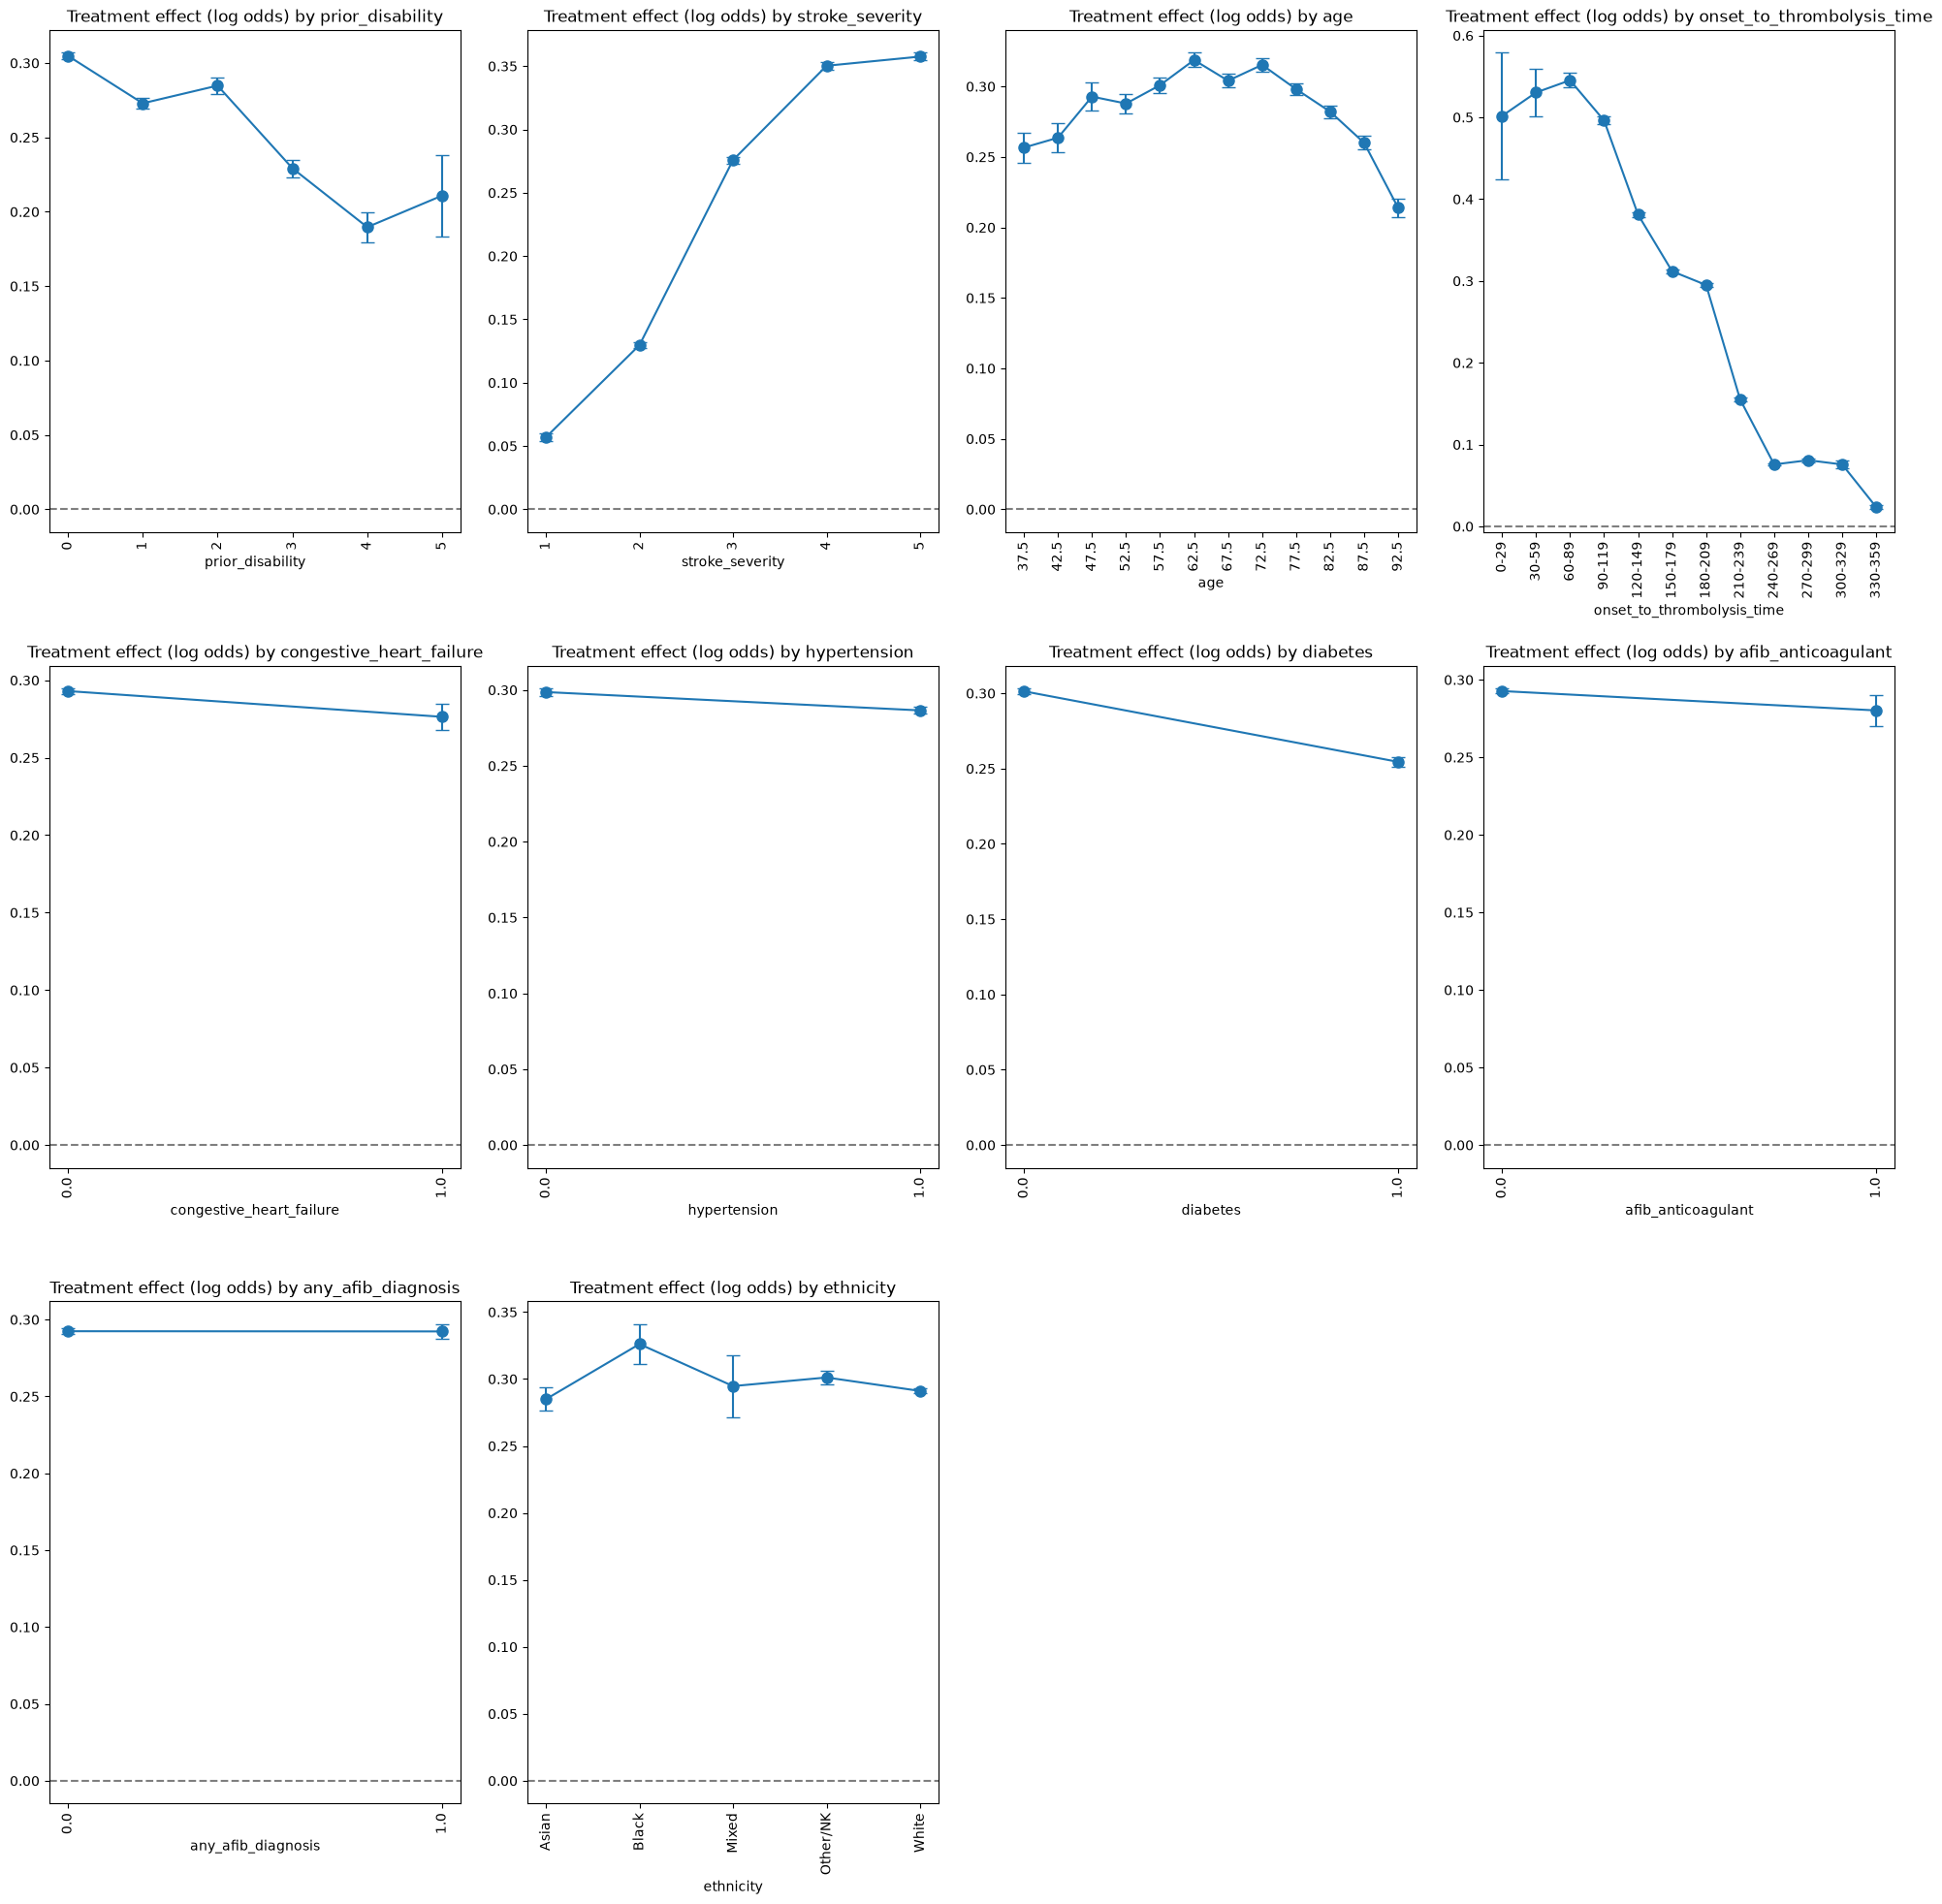

In [13]:
EFFECT_FEATURES = [
    "prior_disability",
    "stroke_severity",
    "age",
    TIME_THROMBOLYSIS,
    "congestive_heart_failure",
    "hypertension",
    "diabetes",
    "afib_anticoagulant",
    "any_afib_diagnosis",
    "ethnicity",
]


def time_bin_labels(starts, width=30):
    """Labels such as '120-149' for binned times."""
    return [f"{start}-{start + width - 1}" for start in starts]


fig, axes = plt.subplots(3, 4, figsize=(20, 20))

for ax, feature in zip(axes.flat, EFFECT_FEATURES):
    plot_df = cf[[feature, "log_odds_diff"]].dropna()
    if feature == TIME_THROMBOLYSIS:
        plot_df[feature] = (plot_df[feature] // 30 * 30).astype(int)

    grouped = plot_df.groupby(feature, observed=True)["log_odds_diff"].agg(["mean", "sem"])
    x_values = np.arange(len(grouped))

    ax.errorbar(x_values, grouped["mean"], yerr=grouped["sem"], fmt="o-", markersize=8, capsize=5)
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_title(f"Treatment effect (log odds) by {feature}")
    ax.set_xlabel(feature)
    ax.set_xticks(x_values)
    ax.tick_params(axis="x", rotation=90)

    if feature == TIME_THROMBOLYSIS:
        ax.set_xticklabels(time_bin_labels(grouped.index))
    elif feature == "stroke_severity":
        ax.set_xticklabels([f"{v:.0f}" for v in grouped.index])
    else:
        ax.set_xticklabels([str(v) for v in grouped.index])

for ax in axes.flat[len(EFFECT_FEATURES):]:
    ax.axis("off")

plt.tight_layout(pad=2)
plt.savefig(output_path("treatment_effects.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.** Estimated benefit (log odds ratio):
* **NIHSS**: rises steeply with severity, from 0.06 at NIHSS 1 to 0.13 at NIHSS 2, 0.28 at NIHSS 3 and 0.35–0.36 at NIHSS 4–5.
* **Time to thrombolysis**: about 0.5–0.55 within 2 hours. It falls to about 0.3 at 2.5–3.5 hours, 0.15 at 3.5–4 hours and about 0.08 at 4–5.5 hours, and is close to zero (0.02) after 5.5 hours.
* **Age**: highest at about 60–75 years (0.30–0.32). It is lower over 80, falling to 0.21 above 90, and slightly lower under 50.
* **Pre-stroke mRS**: 0.30 at mRS 0, falling to about 0.19–0.23 at mRS 3–5.
* **Diabetes**: 0.25 with diabetes vs 0.30 without.
* **Other comorbidities and ethnicity**: little difference.

## 3.2 Benefit by onset-to-thrombolysis time

An ordinary least squares (OLS) regression of individual predicted benefit (log odds ratio) on onset-to-thrombolysis time gives:

* **Benefit at time zero** (the intercept), with 95% CI. This is an extrapolation, because few patients are treated within an hour.
* **Time at which predicted benefit reaches zero**: x = −intercept / slope. Its 95% CI uses the delta method:
Var(x) = Var(a)/b² + a² Var(b)/b⁴ − 2a Cov(a, b)/b³, where a is the intercept and b the slope.
When the zero point lies beyond the observed times this is also an extrapolation.

Note: the 'observations' are model predictions, not independent outcomes, so OLS standard errors and p-values are too small. Section 5.1 gives a bootstrap CI for the time at zero benefit. Treat the regression as a description of how the S-learner's estimated benefit changes with time.

In [14]:
def fit_time_regression(df, time_col=TIME_THROMBOLYSIS, benefit_col="log_odds_diff"):
    """OLS of benefit on time; return the fit and a dict of key quantities with 95% CIs."""
    ols = sm.OLS(df[benefit_col], sm.add_constant(df[[time_col]])).fit()
    intercept, slope = ols.params["const"], ols.params[time_col]
    cov = ols.cov_params()
    intercept_ci = ols.conf_int().loc["const"]

    result = {
        "n": int(ols.nobs),
        "intercept": intercept,
        "intercept CI lower": intercept_ci.iloc[0],
        "intercept CI upper": intercept_ci.iloc[1],
        "slope per hour": slope * 60,
        "R-squared": ols.rsquared,
        "time at zero benefit": np.nan,
        "time at zero CI lower": np.nan,
        "time at zero CI upper": np.nan,
    }
    if not np.isclose(slope, 0):
        x_at_zero = -intercept / slope
        variance = (
            cov.loc["const", "const"] / slope**2
            + intercept**2 * cov.loc[time_col, time_col] / slope**4
            - 2 * intercept * cov.loc["const", time_col] / slope**3
        )
        half_width = 1.96 * np.sqrt(max(variance, 0))
        result.update({
            "time at zero benefit": x_at_zero,
            "time at zero CI lower": x_at_zero - half_width,
            "time at zero CI upper": x_at_zero + half_width,
        })
    return ols, result


ols_time, time_result = fit_time_regression(cf)
print(ols_time.summary())
print(f"\nPredicted benefit at time zero (intercept): {time_result['intercept']:.4f}, "
      f"95% CI: [{time_result['intercept CI lower']:.4f}, {time_result['intercept CI upper']:.4f}]")
print(f"Time at which predicted benefit is zero: {time_result['time at zero benefit']:.0f} mins, "
      f"95% CI: [{time_result['time at zero CI lower']:.0f}, {time_result['time at zero CI upper']:.0f}] mins")

                            OLS Regression Results                            
Dep. Variable:          log_odds_diff   R-squared:                       0.504
Model:                            OLS   Adj. R-squared:                  0.504
Method:                 Least Squares   F-statistic:                 1.360e+04
Date:                Sun, 22 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:01:11   Log-Likelihood:                 7967.2
No. Observations:               13378   AIC:                        -1.593e+04
Df Residuals:                   13376   BIC:                        -1.592e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

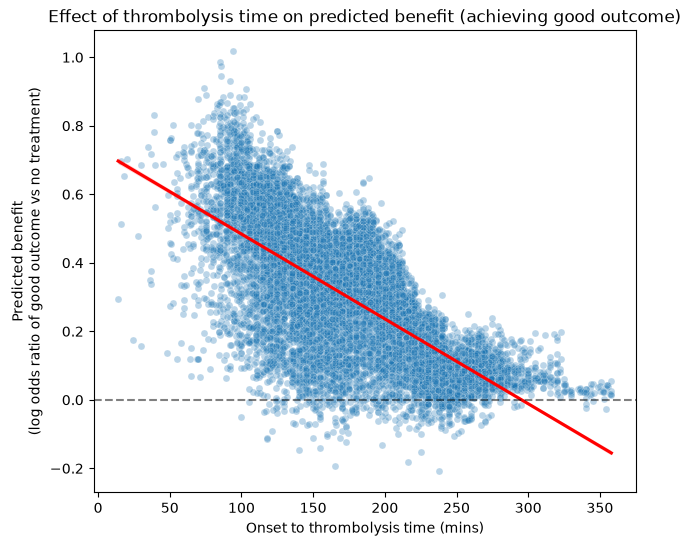

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=cf, x=TIME_THROMBOLYSIS, y="log_odds_diff", s=25, alpha=0.3, ax=ax)
sns.regplot(data=cf, x=TIME_THROMBOLYSIS, y="log_odds_diff", scatter=False, ci=95,
            line_kws={"color": "red"}, ax=ax)
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_title("Effect of thrombolysis time on predicted benefit (achieving good outcome)")
ax.set_xlabel("Onset to thrombolysis time (mins)")
ax.set_ylabel(f"Predicted benefit\n(log odds ratio of good outcome vs no treatment)")
fig.savefig(output_path("thrombolysis_time_effect.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.** Predicted benefit falls by about 0.15 log odds ratio per hour (0.0025 per minute). The extrapolated benefit at time zero is 0.73 (95% CI 0.72 to 0.74; OR about 2.1). The fitted line reaches zero at 295 minutes (95% CI 293 to 298). Time explains about half (R² 0.50) of the variation in individual estimates.

## 3.3 Benefit by onset-to-thrombolysis time, for each NIHSS

The same regression fitted separately for each stroke severity (NIHSS 1 to 5). Lines are drawn over the observed time range for each NIHSS, with 95% confidence bands for the fitted line.

In [16]:
severity_fits, severity_rows = {}, []
for severity in range(1, 6):
    ols, result = fit_time_regression(cf[cf["stroke_severity"] == severity])
    severity_fits[severity] = ols
    severity_rows.append({"stroke_severity": severity, **result})

severity_results = pd.DataFrame(severity_rows).set_index("stroke_severity")
severity_results.to_csv(output_path("time_effect_by_nihss.csv"))
severity_results.round(3)

,n,intercept,intercept CI lower,intercept CI upper,slope per hour,R-squared,time at zero benefit,time at zero CI lower,time at zero CI upper
stroke_severity,,,,,,,,,
1,722,0.194,0.175,0.213,-0.044,0.234,262.698,250.154,275.242
2,1747,0.308,0.296,0.320,-0.059,0.355,313.560,304.504,322.617
3,2784,0.644,0.633,0.655,-0.124,0.636,311.273,307.239,315.307
4,3951,0.852,0.842,0.862,-0.171,0.723,299.600,296.998,302.202
5,4174,0.898,0.887,0.908,-0.186,0.735,290.181,287.860,292.503


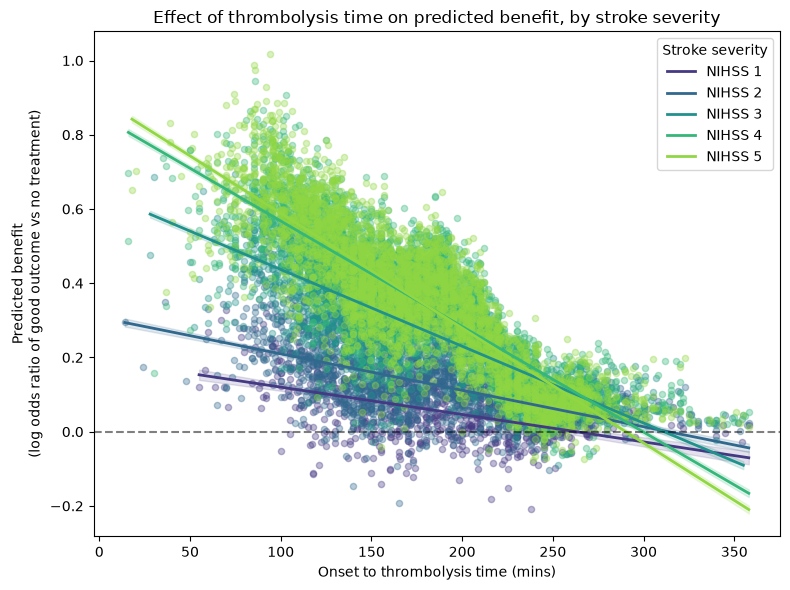

In [17]:
colors = sns.color_palette("viridis", n_colors=5)
fig, ax = plt.subplots(figsize=(8, 6))

for (severity, ols), color in zip(severity_fits.items(), colors):
    group = cf[cf["stroke_severity"] == severity]
    x_grid = np.linspace(group[TIME_THROMBOLYSIS].min(), group[TIME_THROMBOLYSIS].max(), 200)
    prediction = ols.get_prediction(pd.DataFrame({"const": 1.0, TIME_THROMBOLYSIS: x_grid})).summary_frame()

    ax.scatter(group[TIME_THROMBOLYSIS], group["log_odds_diff"], color=color, alpha=0.35, s=20)
    ax.plot(x_grid, prediction["mean"], color=color, linewidth=2, label=f"NIHSS {severity}")
    ax.fill_between(x_grid, prediction["mean_ci_lower"], prediction["mean_ci_upper"], color=color, alpha=0.15)

ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_title("Effect of thrombolysis time on predicted benefit, by stroke severity")
ax.set_xlabel("Onset to thrombolysis time (mins)")
ax.set_ylabel("Predicted benefit\n(log odds ratio of good outcome vs no treatment)")
ax.legend(title="Stroke severity")
fig.tight_layout()
fig.savefig(output_path("thrombolysis_time_effect_by_nihss.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.**

| NIHSS | Thrombolysed | Benefit at time zero (log OR) | Change per hour | R² | Benefit reaches zero (minutes, 95% CI) |
|---|---|---|---|---|---|
| 1 | 722 | 0.19 | −0.04 | 0.23 | 263 (250–275) |
| 2 | 1,747 | 0.31 | −0.06 | 0.36 | 314 (305–323) |
| 3 | 2,784 | 0.64 | −0.12 | 0.64 | 311 (307–315) |
| 4 | 3,951 | 0.85 | −0.17 | 0.72 | 300 (297–302) |
| 5 | 4,174 | 0.90 | −0.19 | 0.74 | 290 (288–293) |

* Benefit for early treatment rises with NIHSS, and the decline with time is steeper at higher NIHSS.
* At **NIHSS 1** the estimated benefit is small at any time, and time explains little of its variation.
* For NIHSS 2–5 the fitted benefit reaches zero at about 4.8–5.2 hours.
* These CIs are too narrow (see Section 3.2). The bootstrap CIs in Section 5.1 are much wider, especially at NIHSS 1.

# 4. Meta-model of benefit

## 4.1 Method

An XGBoost regression model is fitted to the individual estimated benefit (log odds ratio) of thrombolysed patients. It uses the same features as the S-learner, including onset-to-thrombolysis time and stroke team. SHAP values for this meta-model show which characteristics are associated with larger or smaller estimated benefit (treatment-effect heterogeneity), each adjusted for the others.

* In-sample R² is optimistic, because the model is evaluated on its own training data, so a 5-fold out-of-fold R² is also reported.
* The meta-model describes the S-learner's estimates. It cannot find heterogeneity that the S-learner did not estimate, and it inherits any bias in it.

In [18]:
meta_X = cf[X_FIELDS]
meta_y = cf["log_odds_diff"]


def make_meta_model():
    return XGBRegressor(enable_categorical=True, verbosity=0, random_state=RANDOM_STATE, eval_metric="rmse")


meta_model = make_meta_model().fit(meta_X, meta_y)
cf["predicted_log_odds_diff"] = meta_model.predict(meta_X)
cf["oof_predicted_log_odds_diff"] = cross_val_predict(
    make_meta_model(), meta_X, meta_y,
    cv=KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE),
)

r2_in_sample = r2_score(meta_y, cf["predicted_log_odds_diff"])
r2_out_of_fold = r2_score(meta_y, cf["oof_predicted_log_odds_diff"])
print(f"Meta-model R-squared: in-sample {r2_in_sample:.4f}, out-of-fold {r2_out_of_fold:.4f}")

Meta-model R-squared: in-sample 0.9739, out-of-fold 0.8891


**Results.** The meta-model reproduces the S-learner's estimated benefit closely: R² is 0.97 in-sample and 0.89 out-of-fold. Most of the variation in estimated benefit is therefore systematic, i.e. explained by patient features and stroke team, rather than noise. The plot below compares the meta-model's predictions with the S-learner's estimates.

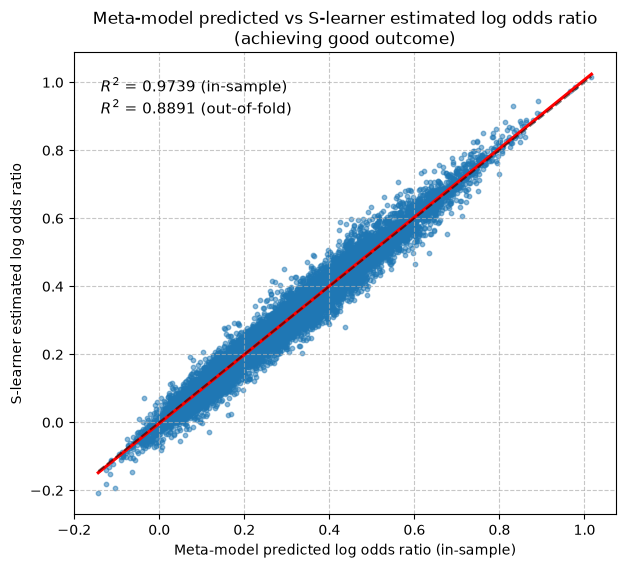

In [19]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.regplot(x="predicted_log_odds_diff", y="log_odds_diff", data=cf, ci=95, ax=ax,
            scatter_kws={"s": 10, "alpha": 0.5}, line_kws={"color": "red"})
limits = [cf["predicted_log_odds_diff"].min(), cf["predicted_log_odds_diff"].max()]
ax.plot(limits, limits, color="black", linestyle="--", alpha=0.5)  # y = x
ax.set_title(f"Meta-model predicted vs S-learner estimated log odds ratio\n(achieving good outcome)")
ax.set_xlabel("Meta-model predicted log odds ratio (in-sample)")
ax.set_ylabel("S-learner estimated log odds ratio")
ax.grid(linestyle="--", alpha=0.7)
ax.text(0.05, 0.95, f"$R^2$ = {r2_in_sample:.4f} (in-sample)\n$R^2$ = {r2_out_of_fold:.4f} (out-of-fold)",
        transform=ax.transAxes, fontsize=11, verticalalignment="top")
plt.show()

## 4.2 SHAP values for the meta-model

Positive SHAP values mean the feature value is associated with *greater* estimated benefit from thrombolysis. The SHAP base value is the value to which the feature SHAP values are added to give each patient's predicted benefit (log odds ratio).

SHAP base value (value the feature SHAP values are added to): 0.292 log odds ratio


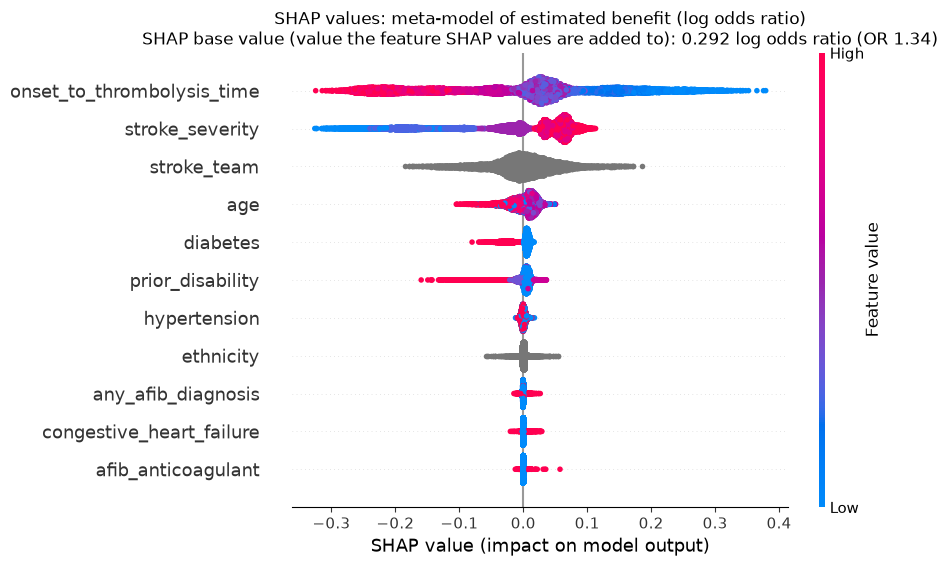

In [20]:
meta_explainer = shap.Explainer(meta_model)
meta_shap_values = meta_explainer(meta_X)
base_value = float(np.ravel(meta_explainer.expected_value)[0])
print(f"SHAP base value (value the feature SHAP values are added to): {base_value:.3f} log odds ratio")

shap.plots.beeswarm(meta_shap_values, max_display=99, show=False)
plt.title(f"SHAP values: meta-model of estimated benefit (log odds ratio)\n"
          f"SHAP base value (value the feature SHAP values are added to): {base_value:.3f} log odds ratio (OR {np.exp(base_value):.2f})")
plt.savefig(output_path("treatment_effect_shap_beeswarm.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.** The SHAP base value (value the feature SHAP values are added to) is 0.29 log odds ratio.
* **Main drivers**: time to thrombolysis and NIHSS are the main drivers of variation in estimated benefit, followed by stroke team and age.
* **Greater benefit**: shorter times and higher NIHSS (4–5).
* **Smaller benefit**: NIHSS 1–2, longer times, older age, diabetes and higher pre-stroke disability.
* **Little effect**: hypertension, atrial fibrillation, anticoagulant use, heart failure and ethnicity.
* **Stroke team**: its contribution is moderate (SHAP mostly within ±0.15). It may partly reflect which mild strokes a team chooses to treat, i.e. selection the model cannot see, rather than true differences in effectiveness.

## 4.3 SHAP values by feature value

There is one panel per feature (stroke team is in the model but not plotted). All panels use the same y-axis scale, and box whiskers show the full range. Thrombolysis time is grouped into 30-minute bins.

* Black dashed line: SHAP = 0 (no change from the SHAP base value).
* Red dotted line: SHAP = −base value. A feature value whose SHAP falls to this line would, on its own, bring the predicted benefit down to zero (if other features did not compensate).

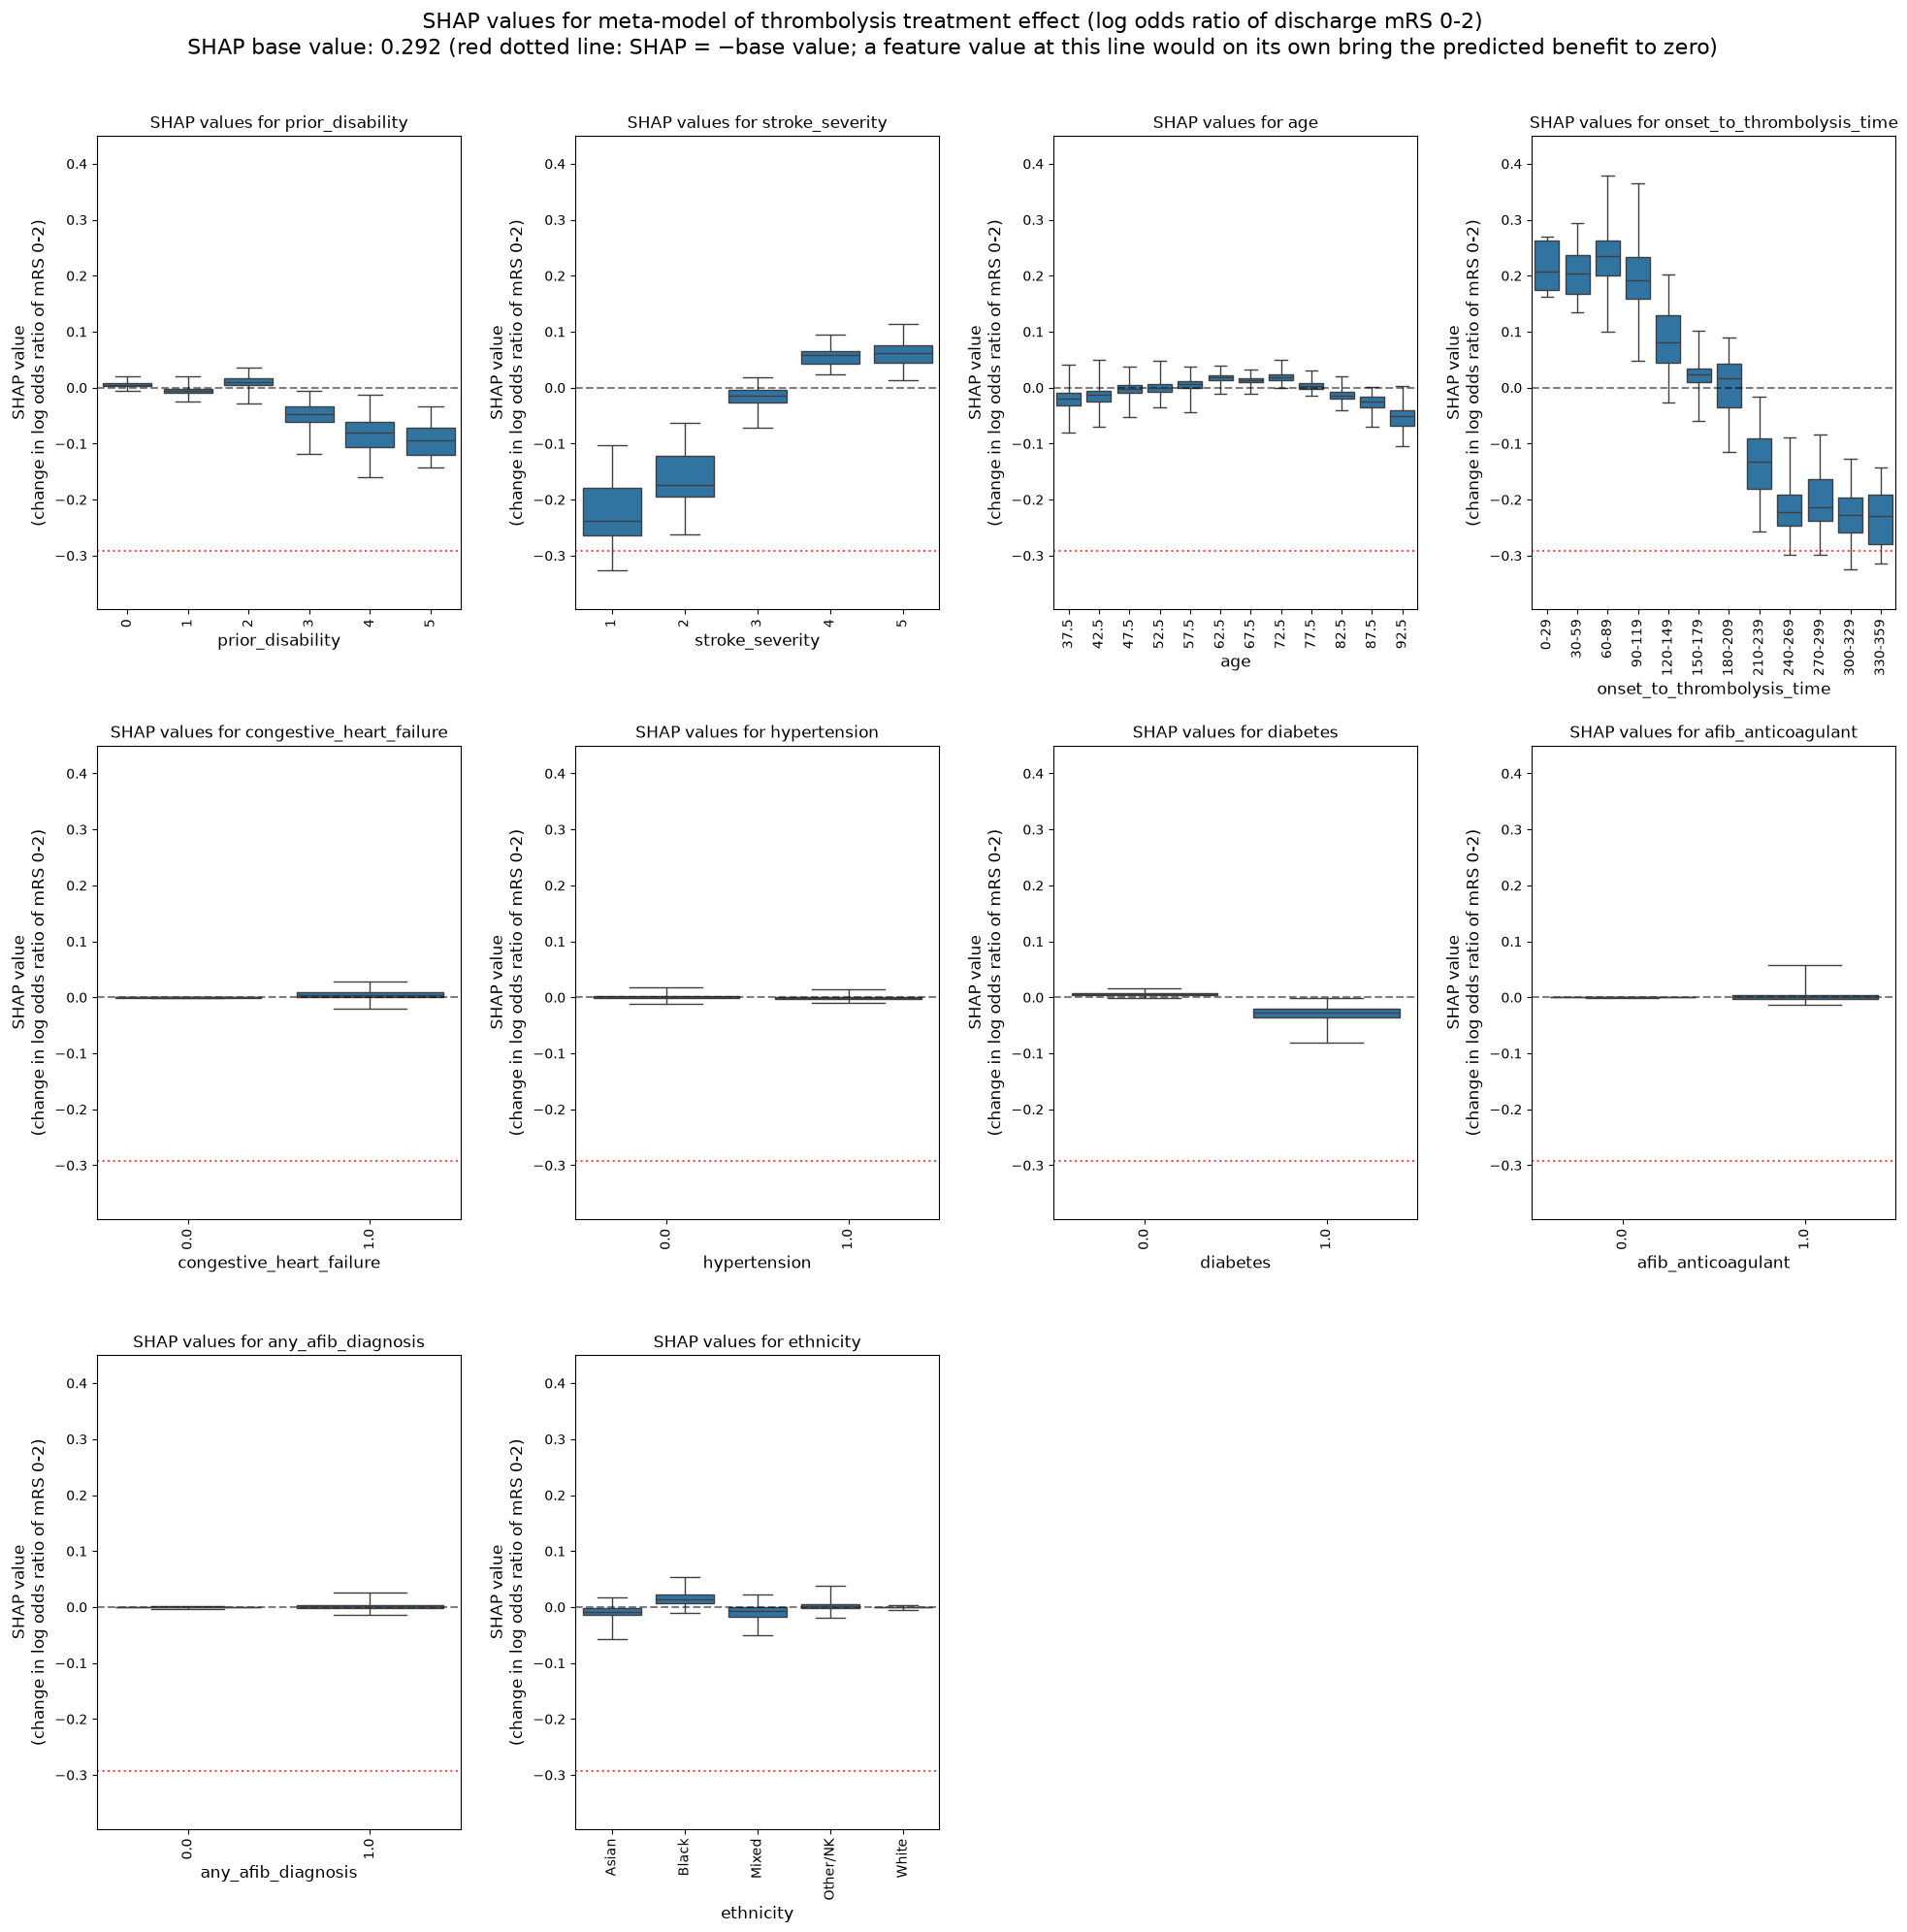

In [21]:
meta_shap_df = pd.DataFrame(meta_shap_values.values, columns=meta_X.columns, index=meta_X.index)

shap_min, shap_max = meta_shap_df.min().min(), meta_shap_df.max().max()
padding = 0.1 * (shap_max - shap_min)
y_limits = (min(shap_min, -base_value) - padding, shap_max + padding)

fig, axes = plt.subplots(3, 4, figsize=(20, 20))

for ax, feature in zip(axes.flat, EFFECT_FEATURES):
    plot_df = pd.DataFrame({
        "feature_value": meta_X[feature].to_numpy(),
        "shap_value": meta_shap_df[feature].to_numpy(),
    }).dropna()
    if feature == TIME_THROMBOLYSIS:
        plot_df["feature_value"] = (pd.to_numeric(plot_df["feature_value"]) // 30 * 30).astype(int)
    order = sorted(plot_df["feature_value"].unique())

    sns.boxplot(data=plot_df, x="feature_value", y="shap_value", order=order, ax=ax, whis=(0, 100))
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.axhline(-base_value, color="red", linestyle="dotted", alpha=0.7)
    ax.set_ylim(y_limits)
    ax.set_title(f"SHAP values for {feature}")
    ax.set_xlabel(feature, fontsize=12)
    ax.set_ylabel(f"SHAP value\n(change in log odds ratio of mRS 0-{MRS_TARGET})", fontsize=12)
    ax.tick_params(axis="x", rotation=90, labelsize=10)

    if feature == TIME_THROMBOLYSIS:
        ax.set_xticklabels(time_bin_labels(order))
    elif feature == "stroke_severity":
        ax.set_xticklabels([f"{float(v):.0f}" for v in order])

for ax in axes.flat[len(EFFECT_FEATURES):]:
    ax.axis("off")

fig.suptitle(
    f"SHAP values for meta-model of thrombolysis treatment effect (log odds ratio of discharge mRS 0-{MRS_TARGET})\n"
    f"SHAP base value: {base_value:.3f} (red dotted line: SHAP = −base value; a feature value at this line would on its own bring the predicted benefit to zero)",
    fontsize=16, y=1.00,
)
plt.tight_layout(pad=2)
plt.savefig(output_path("shap_box_plots_good_outcome.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.**
* **Time to thrombolysis.** It has the largest effect.
  * Treatment within 2 hours adds about +0.2 to the log odds ratio.
  * At 2.5–3.5 hours the contribution is close to zero.
  * After about 4 hours it subtracts 0.2–0.25, which is close to the red line, so late treatment on its own brings the predicted benefit close to zero.
* **NIHSS.**
  * NIHSS 1 subtracts about 0.24, again close to removing all benefit on its own.
  * NIHSS 2 subtracts about 0.15.
  * NIHSS 3 is neutral, and NIHSS 4–5 add about 0.06.
* **Other features.**
  * Pre-stroke mRS 3–5 subtracts about 0.05–0.1.
  * Age over 85 subtracts up to about 0.05.
  * Diabetes subtracts about 0.03.
  * The remaining features have SHAP values close to zero.

# 5. Uncertainty, discrimination and calibration

## 5.1 Uncertainty from refitting the model

The confidence intervals in Sections 2 and 3 reflect variation between patients' predicted effects only. Here the whole pipeline is repeated on `N_BOOT` (30) bootstrap samples of patients, with the tuned hyperparameters held fixed. Each repeat consists of:
* five-fold cross-validation, with copies of the same patient kept in one fold;
* out-of-fold counterfactual predictions for thrombolysed patients;
* the mean effect, overall and by NIHSS;
* the time at which predicted benefit reaches zero.

The 95% CI is the point estimate ± 1.96 × the bootstrap standard deviation. Results are also printed as LaTeX rows.

In [22]:
# Uncertainty in the S-learner effect from refitting the model.
# The confidence intervals above reflect variation between patients' predicted effects only. Here the whole
# pipeline is repeated on N_BOOT bootstrap samples of patients, with the tuned hyperparameters held fixed:
# five-fold cross-validation (copies of the same patient are kept in one fold), out-of-fold counterfactual
# predictions for thrombolysed patients, and the mean effect overall and by NIHSS, and the time at which
# predicted benefit reaches zero. The 95% CI is the point estimate +/- 1.96 x the bootstrap standard deviation.
N_BOOT = 30
EFFECT_GROUPS = ["All"] + [f"NIHSS {s}" for s in range(1, 6)]

def effect_estimates(cf_):
    """Mean effect (probability difference and log odds ratio) and time at zero benefit, overall and by NIHSS."""
    groups = {"All": cf_, **{f"NIHSS {s}": g for s, g in cf_.groupby("stroke_severity")}}
    rows = [{"group": name, "n": len(g),
             "prob_diff": g["treatment_diff_prob"].mean(),
             "log_odds_diff": g["log_odds_diff"].mean(),
             "time_at_zero": fit_time_regression(g)[1]["time at zero benefit"]}
            for name, g in groups.items()]
    return pd.DataFrame(rows).set_index("group").reindex(EFFECT_GROUPS)

point_estimates = effect_estimates(cf)

boot_rng = np.random.default_rng(RANDOM_STATE)
X_all = data[X_FIELDS]
patient_fold = boot_rng.integers(0, N_SPLITS, len(data))  # fold for each original patient
boot_rows = []
for b in range(N_BOOT):
    idx = boot_rng.integers(0, len(data), len(data))
    Xb = X_all.iloc[idx].reset_index(drop=True)
    yb = y.iloc[idx].reset_index(drop=True)
    fold_b = patient_fold[idx]
    folds_b = [(Xb[fold_b != k], Xb[fold_b == k], yb[fold_b != k], yb[fold_b == k]) for k in range(N_SPLITS)]
    models_b, _ = train_and_evaluate(folds_b, xgb_factory(**best_params))
    estimates_b = effect_estimates(predict_thrombolysis_counterfactuals(models_b, folds_b))
    estimates_b["bootstrap"] = b
    boot_rows.append(estimates_b.reset_index())
    print(f"Bootstrap {b + 1}/{N_BOOT} done")

bootstrap_effects = pd.concat(boot_rows, ignore_index=True)
bootstrap_effects.to_csv(output_path("bootstrap_effects.csv"), index=False)

boot_sd = bootstrap_effects.groupby("group")[["prob_diff", "log_odds_diff", "time_at_zero"]].std(ddof=1)
bootstrap_summary = point_estimates.copy()
for col in ["prob_diff", "log_odds_diff", "time_at_zero"]:
    se = boot_sd[col].reindex(bootstrap_summary.index)
    bootstrap_summary[f"{col}_ci_lower"] = bootstrap_summary[col] - 1.96 * se
    bootstrap_summary[f"{col}_ci_upper"] = bootstrap_summary[col] + 1.96 * se
bootstrap_summary["odds_ratio"] = np.exp(bootstrap_summary["log_odds_diff"])
bootstrap_summary["odds_ratio_ci_lower"] = np.exp(bootstrap_summary["log_odds_diff_ci_lower"])
bootstrap_summary["odds_ratio_ci_upper"] = np.exp(bootstrap_summary["log_odds_diff_ci_upper"])
bootstrap_summary.to_csv(output_path("bootstrap_summary.csv"))
display(bootstrap_summary.round(3))

print("% ---- S-learner effects with bootstrap 95% CIs: group & n & pp & log OR & OR ----")
for group, r in bootstrap_summary.iterrows():
    print(f"{group} & {int(r['n']):,} & "
          f"{100 * r['prob_diff']:.1f} ({100 * r['prob_diff_ci_lower']:.1f}--{100 * r['prob_diff_ci_upper']:.1f}) & "
          f"{r['log_odds_diff']:.2f} ({r['log_odds_diff_ci_lower']:.2f}--{r['log_odds_diff_ci_upper']:.2f}) & "
          f"{r['odds_ratio']:.2f} ({r['odds_ratio_ci_lower']:.2f}--{r['odds_ratio_ci_upper']:.2f}) \\\\")

Bootstrap 1/30 done
Bootstrap 2/30 done
Bootstrap 3/30 done
Bootstrap 4/30 done
Bootstrap 5/30 done
Bootstrap 6/30 done
Bootstrap 7/30 done
Bootstrap 8/30 done
Bootstrap 9/30 done
Bootstrap 10/30 done
Bootstrap 11/30 done
Bootstrap 12/30 done
Bootstrap 13/30 done
Bootstrap 14/30 done
Bootstrap 15/30 done
Bootstrap 16/30 done
Bootstrap 17/30 done
Bootstrap 18/30 done
Bootstrap 19/30 done
Bootstrap 20/30 done
Bootstrap 21/30 done
Bootstrap 22/30 done
Bootstrap 23/30 done
Bootstrap 24/30 done
Bootstrap 25/30 done
Bootstrap 26/30 done
Bootstrap 27/30 done
Bootstrap 28/30 done
Bootstrap 29/30 done
Bootstrap 30/30 done


,n,prob_diff,log_odds_diff,time_at_zero,prob_diff_ci_lower,prob_diff_ci_upper,log_odds_diff_ci_lower,log_odds_diff_ci_upper,time_at_zero_ci_lower,time_at_zero_ci_upper,odds_ratio,odds_ratio_ci_lower,odds_ratio_ci_upper
group,,,,,,,,,,,,,
All,13378,0.050,0.292,295.363,0.042,0.059,0.241,0.344,263.216,327.510,1.340,1.273,1.410
NIHSS 1,722,0.007,0.057,262.698,-0.003,0.016,-0.033,0.147,51.917,473.480,1.059,0.968,1.158
NIHSS 2,1747,0.017,0.130,313.560,0.009,0.025,0.062,0.198,246.030,381.091,1.138,1.064,1.219
NIHSS 3,2784,0.042,0.276,311.273,0.033,0.051,0.215,0.337,271.905,350.642,1.318,1.240,1.400
NIHSS 4,3951,0.061,0.350,299.600,0.050,0.071,0.289,0.411,265.923,333.277,1.419,1.336,1.509
NIHSS 5,4174,0.068,0.358,290.181,0.054,0.081,0.286,0.429,261.996,318.367,1.430,1.331,1.536


% ---- S-learner effects with bootstrap 95% CIs: group & n & pp & log OR & OR ----
All & 13,378 & 5.0 (4.2--5.9) & 0.29 (0.24--0.34) & 1.34 (1.27--1.41) \\
NIHSS 1 & 722 & 0.7 (-0.3--1.6) & 0.06 (-0.03--0.15) & 1.06 (0.97--1.16) \\
NIHSS 2 & 1,747 & 1.7 (0.9--2.5) & 0.13 (0.06--0.20) & 1.14 (1.06--1.22) \\
NIHSS 3 & 2,784 & 4.2 (3.3--5.1) & 0.28 (0.21--0.34) & 1.32 (1.24--1.40) \\
NIHSS 4 & 3,951 & 6.1 (5.0--7.1) & 0.35 (0.29--0.41) & 1.42 (1.34--1.51) \\
NIHSS 5 & 4,174 & 6.8 (5.4--8.1) & 0.36 (0.29--0.43) & 1.43 (1.33--1.54) \\


**Results.** Effects in thrombolysed patients, with bootstrap 95% CIs that include model uncertainty:

| Group | n | Benefit (percentage points) | log OR | OR | Benefit reaches zero (minutes) |
|---|---|---|---|---|---|
| All | 13,378 | 5.0 (4.2 to 5.9) | 0.29 (0.24 to 0.34) | 1.34 (1.27 to 1.41) | 295 (263 to 328) |
| NIHSS 1 | 722 | 0.7 (−0.3 to 1.6) | 0.06 (−0.03 to 0.15) | 1.06 (0.97 to 1.16) | 263 (52 to 473) |
| NIHSS 2 | 1,747 | 1.7 (0.9 to 2.5) | 0.13 (0.06 to 0.20) | 1.14 (1.06 to 1.22) | 314 (246 to 381) |
| NIHSS 3 | 2,784 | 4.2 (3.3 to 5.1) | 0.28 (0.21 to 0.34) | 1.32 (1.24 to 1.40) | 311 (272 to 351) |
| NIHSS 4 | 3,951 | 6.1 (5.0 to 7.1) | 0.35 (0.29 to 0.41) | 1.42 (1.34 to 1.51) | 300 (266 to 333) |
| NIHSS 5 | 4,174 | 6.8 (5.4 to 8.1) | 0.36 (0.29 to 0.43) | 1.43 (1.33 to 1.54) | 290 (262 to 318) |

* Including model uncertainty widens the CIs considerably: for the overall effect, from ±0.07 to about ±0.85 percentage points.
* The average benefit, and the benefit at NIHSS 2–5, remain clearly above zero.
* **At NIHSS 1 the CI includes no effect**, and the time at zero benefit cannot be estimated with any precision.
* The time at which benefit reaches zero is about 4.4 to 5.5 hours overall (bootstrap CI).

## 5.2 Discrimination and calibration

These checks use the primary model's out-of-fold predictions for all patients, with the treatment actually received:
* ROC AUC, with a bootstrap 95% CI;
* calibration by decile of predicted probability;
* the calibration intercept (calibration-in-the-large; 0 is ideal) and slope (1 is ideal), each with a bootstrap 95% CI.

Calibration matters here because treatment effects are differences between predicted probabilities.

,estimate,ci_lower,ci_upper
ROC AUC,0.724,0.719,0.727
Calibration intercept,0.000,-0.016,0.013
Calibration slope,0.980,0.949,0.996


,n,predicted,observed
decile,,,
1,5839,0.422,0.425
2,5839,0.567,0.578
3,5838,0.650,0.655
4,5839,0.711,0.711
5,5839,0.760,0.753
6,5838,0.802,0.801
7,5839,0.838,0.838
8,5838,0.870,0.865
9,5840,0.902,0.896


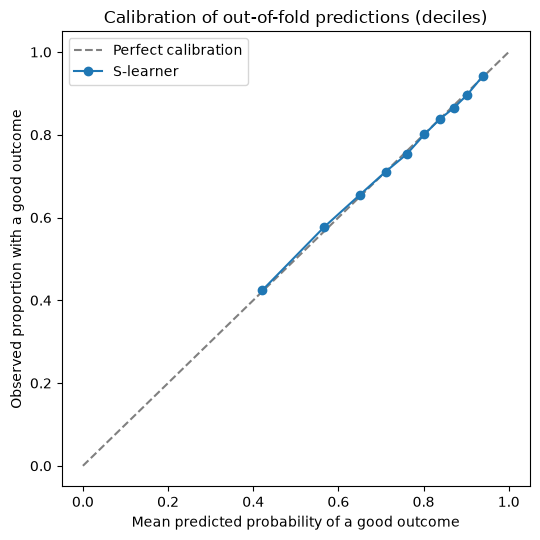

In [23]:
# Discrimination and calibration of the primary model's out-of-fold predictions (all patients, actual treatment):
# ROC AUC, calibration intercept and slope (each with a bootstrap 95% CI), and calibration by decile.
oof_y = pd.concat([test_y for (_, _, _, test_y) in folds]).to_numpy()
oof_p = np.concatenate([model.predict_proba(test_X)[:, 1] for model, (_, test_X, _, _) in zip(models, folds)])

def calibration_intercept_slope(y_true, prob):
    """Calibration intercept (calibration-in-the-large, slope fixed at 1) and slope (logistic
    recalibration of the outcome on the logit of the predicted probability)."""
    logit = to_log_odds(prob)
    slope = LogisticRegression(C=1e12, max_iter=1000).fit(logit.reshape(-1, 1), y_true).coef_[0, 0]
    a = 0.0  # intercept with the slope fixed at 1: Newton iterations for the offset model
    for _ in range(50):
        p = 1 / (1 + np.exp(-(a + logit)))
        a += (y_true - p).sum() / (p * (1 - p)).sum()
    return a, slope

def bootstrap_performance(y_true, prob, n_boot=N_BOOT, seed=RANDOM_STATE):
    """Point estimates and percentile 95% CIs for ROC AUC and calibration intercept and slope."""
    rng = np.random.default_rng(seed)
    point = [roc_auc_score(y_true, prob), *calibration_intercept_slope(y_true, prob)]
    draws = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        draws.append([roc_auc_score(y_true[i], prob[i]), *calibration_intercept_slope(y_true[i], prob[i])])
    draws = np.array(draws)
    return pd.DataFrame({
        "estimate": point,
        "ci_lower": np.percentile(draws, 2.5, axis=0),
        "ci_upper": np.percentile(draws, 97.5, axis=0),
    }, index=["ROC AUC", "Calibration intercept", "Calibration slope"])

def calibration_by_decile(y_true, prob):
    """Mean predicted probability and observed proportion in each decile of predicted probability."""
    decile = pd.qcut(prob, 10, labels=False, duplicates="drop")
    return (pd.DataFrame({"decile": decile + 1, "predicted": prob, "observed": y_true})
            .groupby("decile").agg(n=("observed", "size"), predicted=("predicted", "mean"),
                                   observed=("observed", "mean")))

s_learner_performance = bootstrap_performance(oof_y, oof_p)
s_learner_calibration = calibration_by_decile(oof_y, oof_p)
s_learner_performance.to_csv(output_path("performance_bootstrap.csv"))
s_learner_calibration.to_csv(output_path("calibration_deciles.csv"))
display(s_learner_performance.round(3))
display(s_learner_calibration.round(3))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")
ax.plot(s_learner_calibration["predicted"], s_learner_calibration["observed"], "o-", label="S-learner")
ax.set_xlabel("Mean predicted probability of a good outcome")
ax.set_ylabel("Observed proportion with a good outcome")
ax.set_title("Calibration of out-of-fold predictions (deciles)")
ax.legend()
fig.tight_layout()
fig.savefig(output_path("calibration.png"), dpi=300)
plt.show()

**Results.**
* **Discrimination.** ROC AUC is 0.724 (95% CI 0.719 to 0.727), which is moderate.
* **Calibration.** It is very good:
  * calibration intercept 0.00 (−0.016 to 0.013);
  * calibration slope 0.98 (0.95 to 1.00), i.e. very slight over-dispersion of predictions;
  * observed and predicted rates agree within about 1 percentage point in every decile, from 42% in the lowest decile to 94% in the highest.

# 6. Sensitivity analysis

The S-learner estimates rest on assumptions and analytic choices. This section tests how far the main results (average benefit, benefit by time and by NIHSS) depend on them.

| Concern | Analysis |
|---|---|
| **Positivity / overlap**: are there comparable untreated patients for thrombolysed patients? | S1: propensity model for thrombolysis; check its distribution; re-estimate after trimming extreme propensities (in S2). |
| **Analytic choices**: hyperparameters, class weighting, fold allocation, outcome definition, covariate set, population, model flexibility, model class | S2: re-run the pipeline under alternative specifications and compare. |
| **Unmeasured confounding**, e.g. whether the deficit is disabling (not captured by NIHSS), imaging findings, antiplatelet strategy | S3: E-values, overall, by time to thrombolysis and by NIHSS. |
| **Unmeasured confounding**, on the scale of explained variance, with measured covariates as benchmarks | S4: sensemakr robustness values, benchmark bounds and contour plots, overall and by NIHSS. |
| **Dependence on measured confounders** | S5: leave NIHSS, age or pre-stroke mRS out of the model in turn. |
| **Other designs** | S6: further options (not run here). |

Runtime: S2 fits 5 models for each of 14 scenarios and S5 for each of 3, so they take several minutes. Model uncertainty (bootstrap confidence intervals) is assessed in Section 5.1.

## S1. Overlap (positivity)

An XGBoost classifier predicts the probability of receiving thrombolysis (the propensity) from the adjustment features, using out-of-fold predictions. The S-learner must extrapolate when it predicts a patient's counterfactual outcome if either of these holds:
* the propensity distributions of thrombolysed and untreated patients are very different;
* many patients have propensities near 0 or 1.

Patients outside `PROPENSITY_TRIM` (0.05–0.95) are counted below by NIHSS and treatment, and are excluded in the propensity-trimmed scenario in S2.

Propensity model AUC (out-of-fold): 0.789


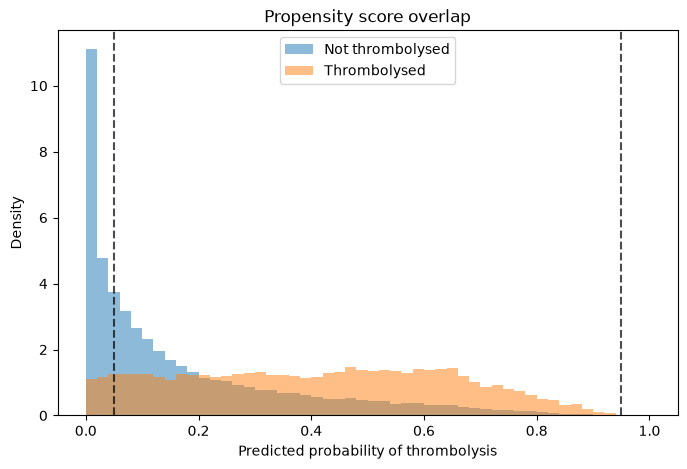

n outside trim range      proportion outside trim range  \
thrombolysis_given                    0    1                             0   
stroke_severity                                                              
1                                  5961  230                         0.580   
2                                  4820  212                         0.389   
3                                  2618  161                         0.260   
4                                  1559   86                         0.222   
5                                  1142   88                         0.218   

                           
thrombolysis_given      1  
stroke_severity            
1                   0.319  
2                   0.121  
3                   0.058  
4                   0.022  
5                   0.021

In [24]:
PROPENSITY_TRIM = (0.05, 0.95)
propensity_features = ADJUSTMENT_FEATURES + CATEGORICAL_FEATURES

data["propensity_thrombolysis"] = cross_val_predict(
    XGBClassifier(enable_categorical=True, verbosity=0, random_state=RANDOM_STATE, eval_metric="logloss"),
    data[propensity_features], data["thrombolysis_given"],
    cv=StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE),
    method="predict_proba",
)[:, 1]

print(f"Propensity model AUC (out-of-fold): "
      f"{roc_auc_score(data['thrombolysis_given'], data['propensity_thrombolysis']):.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
for label, value in [("Not thrombolysed", 0), ("Thrombolysed", 1)]:
    ax.hist(data.loc[data["thrombolysis_given"] == value, "propensity_thrombolysis"],
            bins=50, range=(0, 1), density=True, alpha=0.5, label=label)
for limit in PROPENSITY_TRIM:
    ax.axvline(limit, color="black", linestyle="--", alpha=0.7)
ax.set_xlabel("Predicted probability of thrombolysis")
ax.set_ylabel("Density")
ax.set_title("Propensity score overlap")
ax.legend()
fig.savefig(output_path("sensitivity_propensity_overlap.png"), dpi=300, bbox_inches="tight")
plt.show()

outside_trim = ~data["propensity_thrombolysis"].between(*PROPENSITY_TRIM)
(
    outside_trim.groupby([data["stroke_severity"], data["thrombolysis_given"]])
    .agg(["sum", "mean"])
    .rename(columns={"sum": "n outside trim range", "mean": "proportion outside trim range"})
    .unstack("thrombolysis_given")
    .round(3)
)

**Results.** The propensity model has an out-of-fold AUC of 0.79, so treatment is fairly predictable from the measured features.

Overlap is poor at NIHSS 1, where most propensities outside the range are very low:
* 58% of untreated patients fall outside 0.05–0.95;
* 32% of thrombolysed patients (230 of 722) fall outside.

Overlap improves with severity. The proportion of thrombolysed patients outside the range is:
* 12% at NIHSS 2;
* 6% at NIHSS 3;
* 2% at NIHSS 4–5.

Estimates at NIHSS 1, and to a lesser degree NIHSS 2, therefore rely most on model extrapolation.

## S2. Robustness to analytic choices

`run_thrombolysis_analysis` repeats the whole pipeline (outcome, 5-fold S-learner, counterfactual predictions) with one setting changed at a time. For each scenario it reports:
* the mean benefit (log odds and probability);
* the regression of benefit on time (slope per hour, and the time at which benefit reaches zero);
* the mean benefit by NIHSS.

| Scenario | What it tests |
|---|---|
| Base case | Reproduces the main analysis: tuned hyperparameters, no class weighting (check) |
| Original specification (default, weighted) | Default XGBoost settings with class weighting (`scale_pos_weight` = negatives / positives × `POS_WEIGHT_FACTOR`). Tests hyperparameter choice and class weighting together. |
| Default XGBoost, no class weighting | Default settings alone. Separates the effect of class weighting from the effect of tuning. |
| CV seed 1, CV seed 2 | Variability due to the random allocation of patients to folds |
| Outcome: mRS 0–2 only | Dropping the 'no worse than pre-stroke' rule |
| Outcome: mRS 0–1 or no worse | A stricter (excellent) outcome, commonly used in mild-stroke trials |
| Outcome: mRS 0–3 or no worse | A more lenient definition of good outcome |
| Without stroke team | Team captures local practice and case mix; removing it shows how much estimates rely on within-team comparisons |
| Pre-stroke mRS 0–2 only | Restricts to previously independent patients, where the 'no worse than pre-stroke' rule rarely applies |
| Arrival within 3 hours | Earlier arrivals only |
| Propensity-trimmed (0.05–0.95) | Restricts to patients with overlap (see S1) |
| Regularised XGBoost | A fixed, heavily regularised specification (depth 3, 300 trees, learning rate 0.05, min child weight 10), unweighted: a further check on model flexibility |
| Logistic regression S-learner | A parametric model: main effects plus a thrombolysis indicator and a linear time-to-thrombolysis term among treated patients. It tests model class, and gives a constant log odds ratio at a given time. |

Hyperparameters are not re-tuned for each scenario: scenarios that use the base model use the tuned settings.

In [25]:
def encode_thrombolysis(X):
    """For linear models: thrombolysis indicator, and time set to 0 when not given (so time only acts among treated)."""
    X = X.copy()
    given = X[TIME_THROMBOLYSIS] < NO_TREATMENT
    X["thrombolysis_indicator"] = given.astype(float)
    X[TIME_THROMBOLYSIS] = X[TIME_THROMBOLYSIS].where(given, 0.0)
    return X


def logistic_factory():
    """Logistic regression S-learner (main effects; numeric scaled, categorical one-hot encoded)."""
    def make_model(train_y):
        preprocess = ColumnTransformer([
            ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
             make_column_selector(dtype_exclude=["category", "object"])),
            ("categorical", make_pipeline(FunctionTransformer(lambda X: X.astype(str)),
                                          OneHotEncoder(handle_unknown="ignore")),
             make_column_selector(dtype_include=["category", "object"])),
        ])
        return make_pipeline(FunctionTransformer(encode_thrombolysis), preprocess,
                             LogisticRegression(max_iter=2000))
    return make_model


def run_thrombolysis_analysis(df, mrs_target=MRS_TARGET, include_no_worse=True,
                              features=None, model_factory=None, random_state=RANDOM_STATE):
    """Re-run the S-learner pipeline with alternative settings; return counterfactuals and performance."""
    features = features if features is not None else X_FIELDS
    model_factory = model_factory if model_factory is not None else xgb_factory(**best_params)
    outcome = good_outcome(df, mrs_target=mrs_target, include_no_worse=include_no_worse)
    scenario_folds = split_folds(df[features], outcome, random_state=random_state)
    scenario_models, scenario_performance = train_and_evaluate(scenario_folds, model_factory)
    return predict_thrombolysis_counterfactuals(scenario_models, scenario_folds), scenario_performance


SCENARIOS = {
    "Base case": {},
    "Original specification (default, weighted)": {"model_factory": xgb_factory(POS_WEIGHT_FACTOR)},
    "Default XGBoost, no class weighting": {"model_factory": xgb_factory(pos_weight_factor=None)},
    "CV seed 1": {"random_state": 1},
    "CV seed 2": {"random_state": 2},
    "Outcome: mRS 0-2 only": {"include_no_worse": False},
    "Outcome: mRS 0-1 or no worse": {"mrs_target": 1},
    "Outcome: mRS 0-3 or no worse": {"mrs_target": 3},
    "Without stroke team": {"features": [f for f in X_FIELDS if f != "stroke_team"]},
    "Pre-stroke mRS 0-2 only": {"population": lambda df: df[df["prior_disability"] <= 2]},
    "Arrival within 3 hours": {"population": lambda df: df[df["onset_to_arrival_time"] < 180]},
    "Propensity-trimmed (0.05-0.95)": {
        "population": lambda df: df[df["propensity_thrombolysis"].between(*PROPENSITY_TRIM)]
    },
    "Regularised XGBoost": {"model_factory": xgb_factory(
        None, max_depth=3, n_estimators=300, learning_rate=0.05, min_child_weight=10
    )},
    "Logistic regression S-learner": {"model_factory": logistic_factory()},
}

overall_rows, severity_rows = [], []

for scenario, settings in SCENARIOS.items():
    settings = dict(settings)
    population = settings.pop("population", None)
    scenario_data = population(data) if population is not None else data

    scenario_cf, scenario_performance = run_thrombolysis_analysis(scenario_data, **settings)

    log_odds = summarise_effect(scenario_cf["log_odds_diff"])
    prob = summarise_effect(scenario_cf["treatment_diff_prob"])
    _, time_fit = fit_time_regression(scenario_cf)
    overall_rows.append({
        "scenario": scenario,
        "patients": len(scenario_data),
        "thrombolysed": int(log_odds["n"]),
        "mean AUC": scenario_performance["AUC"].mean(),
        "observed positive rate": scenario_performance["actual_positive_rate"].mean(),
        "mean predicted probability": scenario_performance["mean_predicted_probability"].mean(),
        "log OR mean": log_odds["mean"],
        "log OR CI lower": log_odds["95% CI lower"],
        "log OR CI upper": log_odds["95% CI upper"],
        "prob diff mean": prob["mean"],
        "prob diff CI lower": prob["95% CI lower"],
        "prob diff CI upper": prob["95% CI upper"],
        "proportion negative effect": log_odds["proportion < 0"],
        "log OR slope per hour": time_fit["slope per hour"],
        "time at zero benefit": time_fit["time at zero benefit"],
        "time at zero CI lower": time_fit["time at zero CI lower"],
        "time at zero CI upper": time_fit["time at zero CI upper"],
    })

    by_severity = scenario_cf.groupby("stroke_severity")["log_odds_diff"].apply(summarise_effect).unstack()
    by_severity["scenario"] = scenario
    severity_rows.append(by_severity.reset_index())
    print(f"Completed: {scenario}")

sensitivity_overall = pd.DataFrame(overall_rows).set_index("scenario")
sensitivity_by_severity = pd.concat(severity_rows, ignore_index=True)
sensitivity_overall.to_csv(output_path("sensitivity_overall.csv"))
sensitivity_by_severity.to_csv(output_path("sensitivity_by_nihss.csv"), index=False)

Completed: Base case
Completed: Original specification (default, weighted)
Completed: Default XGBoost, no class weighting
Completed: CV seed 1
Completed: CV seed 2
Completed: Outcome: mRS 0-2 only
Completed: Outcome: mRS 0-1 or no worse
Completed: Outcome: mRS 0-3 or no worse
Completed: Without stroke team
Completed: Pre-stroke mRS 0-2 only
Completed: Arrival within 3 hours
Completed: Propensity-trimmed (0.05-0.95)
Completed: Regularised XGBoost
Completed: Logistic regression S-learner


### Model performance and overall benefit by scenario

The first table gives each scenario's sample, out-of-fold AUC and calibration in the large. The second gives the mean benefit with 95% CI (between-patient variation only), the proportion of negative individual estimates, and the time regression. The figure compares scenarios.

In [26]:
sensitivity_overall[["patients", "thrombolysed", "mean AUC", "observed positive rate", "mean predicted probability"]].round(3)

,patients,thrombolysed,mean AUC,observed positive rate,mean predicted probability
scenario,,,,,
Base case,58387,13378,0.724,0.746,0.746
"Original specification (default, weighted)",58387,13378,0.691,0.746,0.599
"Default XGBoost, no class weighting",58387,13378,0.691,0.746,0.749
CV seed 1,58387,13378,0.724,0.746,0.746
CV seed 2,58387,13378,0.724,0.746,0.746
Outcome: mRS 0-2 only,58387,13378,0.816,0.666,0.666
Outcome: mRS 0-1 or no worse,58387,13378,0.712,0.562,0.562
Outcome: mRS 0-3 or no worse,58387,13378,0.763,0.877,0.877
Without stroke team,58387,13378,0.697,0.746,0.746


In [27]:
sensitivity_overall[[
    "log OR mean", "log OR CI lower", "log OR CI upper",
    "prob diff mean", "prob diff CI lower", "prob diff CI upper",
    "proportion negative effect", "log OR slope per hour",
    "time at zero benefit", "time at zero CI lower", "time at zero CI upper",
]].round(3)

,log OR mean,log OR CI lower,log OR CI upper,prob diff mean,prob diff CI lower,prob diff CI upper,proportion negative effect,log OR slope per hour,time at zero benefit,time at zero CI lower,time at zero CI upper
scenario,,,,,,,,,,,
Base case,0.292,0.289,0.296,0.050,0.050,0.051,0.023,-0.149,295.363,293.179,297.547
"Original specification (default, weighted)",0.588,0.573,0.603,0.101,0.099,0.104,0.248,-0.305,293.028,286.523,299.533
"Default XGBoost, no class weighting",0.499,0.483,0.514,0.058,0.055,0.060,0.293,-0.259,292.634,284.675,300.593
CV seed 1,0.289,0.286,0.293,0.050,0.049,0.051,0.024,-0.147,295.336,293.088,297.584
CV seed 2,0.290,0.287,0.293,0.050,0.049,0.050,0.025,-0.151,292.735,290.624,294.845
Outcome: mRS 0-2 only,0.305,0.302,0.309,0.051,0.050,0.052,0.038,-0.143,305.738,302.954,308.522
Outcome: mRS 0-1 or no worse,0.285,0.282,0.287,0.063,0.062,0.063,0.006,-0.117,322.853,320.291,325.416
Outcome: mRS 0-3 or no worse,0.261,0.257,0.264,0.023,0.022,0.023,0.067,-0.154,278.734,276.821,280.647
Without stroke team,0.287,0.284,0.291,0.050,0.050,0.051,0.066,-0.119,321.627,317.530,325.725


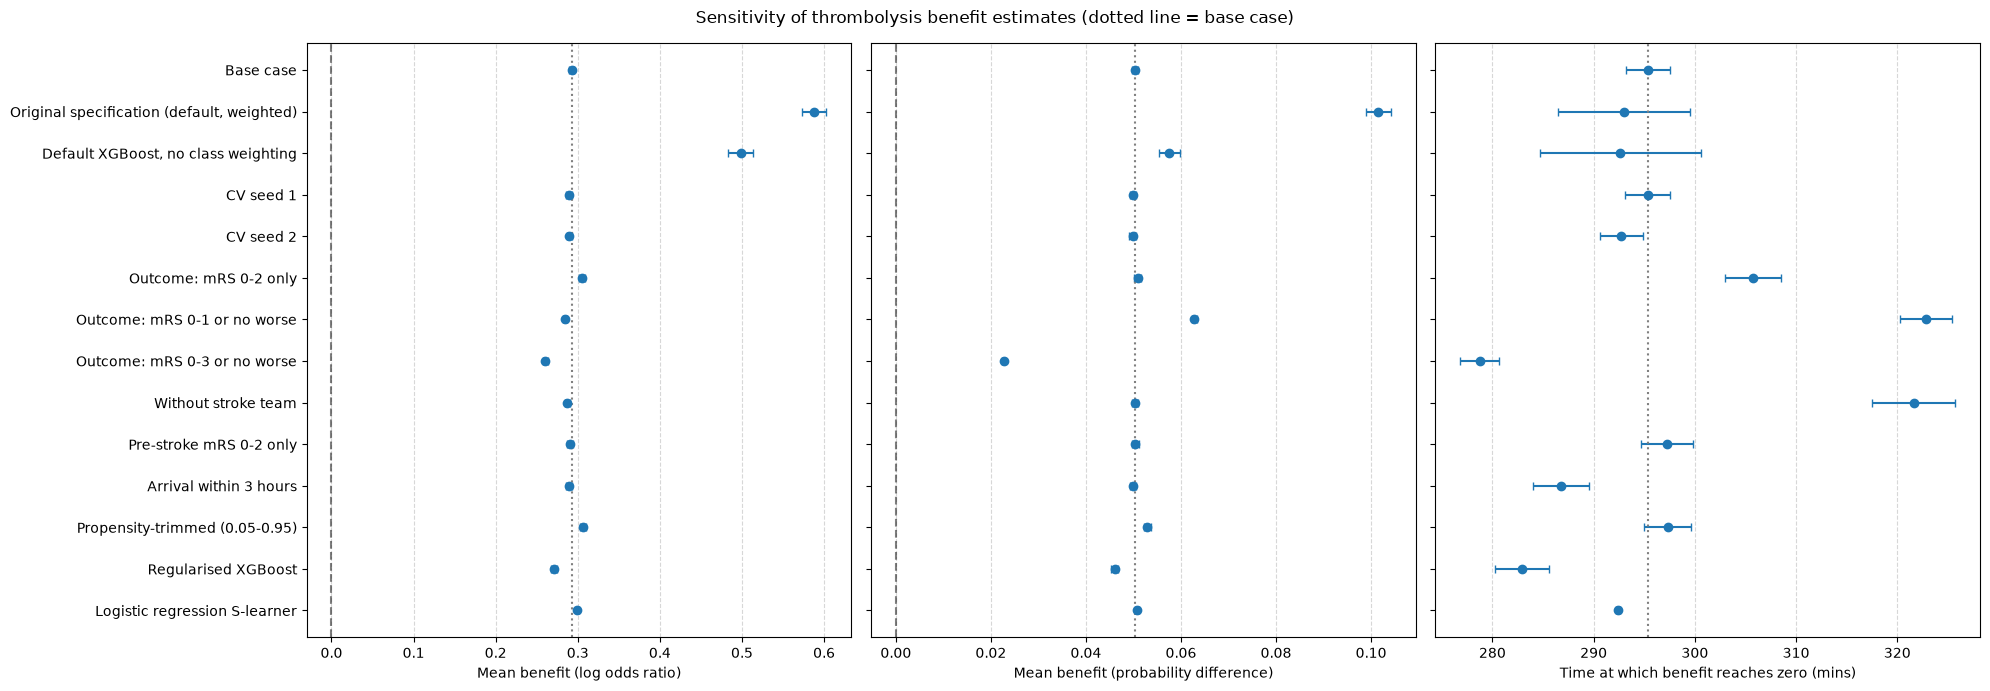

In [28]:
scenarios = list(SCENARIOS)
y_pos = np.arange(len(scenarios))[::-1]
res = sensitivity_overall.reindex(scenarios)

panels = [
    ("log OR", "Mean benefit (log odds ratio)"),
    ("prob diff", "Mean benefit (probability difference)"),
    ("time at zero", "Time at which benefit reaches zero (mins)"),
]
fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharey=True)
for ax, (prefix, xlabel) in zip(axes, panels):
    mean_col = f"{prefix} mean" if prefix != "time at zero" else "time at zero benefit"
    ax.errorbar(
        res[mean_col], y_pos,
        xerr=[res[mean_col] - res[f"{prefix} CI lower"], res[f"{prefix} CI upper"] - res[mean_col]],
        fmt="o", capsize=3,
    )
    ax.axvline(res.loc["Base case", mean_col], color="grey", linestyle=":")
    if prefix != "time at zero":
        ax.axvline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(scenarios)
fig.suptitle("Sensitivity of thrombolysis benefit estimates (dotted line = base case)")
fig.tight_layout()
fig.savefig(output_path("sensitivity_overall.png"), dpi=300, bbox_inches="tight")
plt.show()

### Benefit by NIHSS across scenarios

Mean log odds ratio (with 95% CI) by NIHSS for each scenario. This checks whether the pattern of benefit by severity, in particular any lack of benefit at NIHSS 1-2, is robust.

stroke_severity,1,2,3,4,5
scenario,,,,,
Base case,0.057,0.130,0.276,0.350,0.358
"Original specification (default, weighted)",0.212,0.335,0.594,0.667,0.681
"Default XGBoost, no class weighting",0.070,0.251,0.517,0.569,0.597
CV seed 1,0.045,0.120,0.274,0.349,0.356
CV seed 2,0.049,0.130,0.263,0.350,0.359
Outcome: mRS 0-2 only,0.030,0.108,0.275,0.363,0.401
Outcome: mRS 0-1 or no worse,0.114,0.169,0.273,0.340,0.318
Outcome: mRS 0-3 or no worse,0.050,0.129,0.209,0.316,0.335
Without stroke team,-0.023,0.100,0.278,0.365,0.352


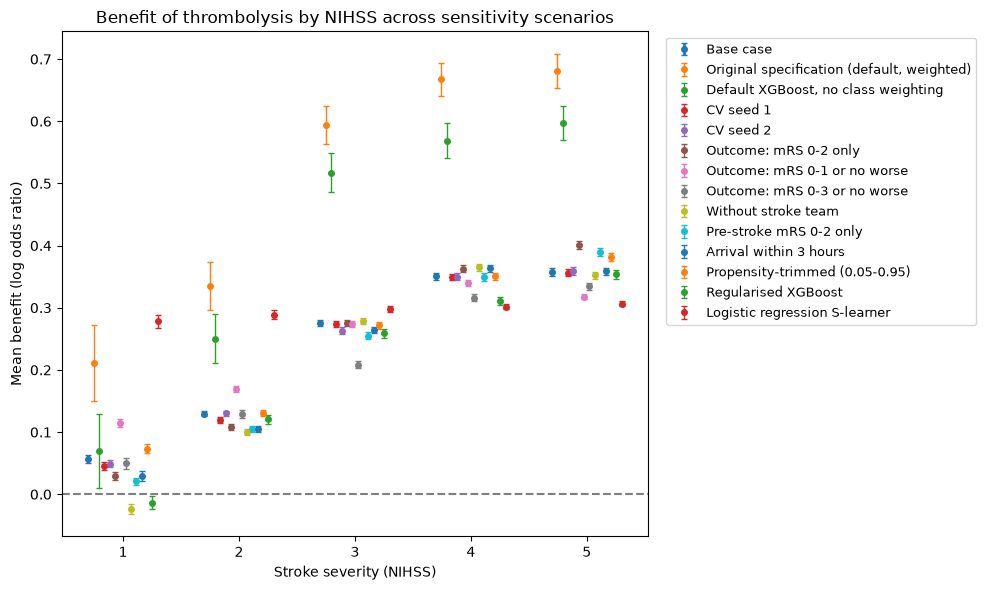

In [29]:
display(
    sensitivity_by_severity.pivot(index="scenario", columns="stroke_severity", values="mean")
    .reindex(scenarios).round(3)
)

fig, ax = plt.subplots(figsize=(10, 6))
offsets = np.linspace(-0.3, 0.3, len(scenarios))
for offset, scenario in zip(offsets, scenarios):
    s = sensitivity_by_severity[sensitivity_by_severity["scenario"] == scenario]
    ax.errorbar(
        s["stroke_severity"] + offset, s["mean"],
        yerr=[s["mean"] - s["95% CI lower"], s["95% CI upper"] - s["mean"]],
        fmt="o", capsize=2, markersize=4, label=scenario,
        linewidth=2 if scenario == "Base case" else 1,
    )
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_xticks(range(1, 6))
ax.set_xlabel("Stroke severity (NIHSS)")
ax.set_ylabel("Mean benefit (log odds ratio)")
ax.set_title("Benefit of thrombolysis by NIHSS across sensitivity scenarios")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(output_path("sensitivity_by_nihss.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.**

* **Robust average benefit.** With the primary outcome definition, the mean log odds ratio is 0.27–0.31 (4.6 to 5.3 percentage points) in every tuned, regularised or logistic scenario. These cover:
  * fold seeds;
  * removing stroke team;
  * previously independent patients only;
  * arrival within 3 hours;
  * propensity trimming;
  * the fixed regularised XGBoost;
  * the logistic regression S-learner.

  Fold seeds change the estimate by less than 0.005.
* **Outcome definitions.** The log odds ratio is similar across them (0.26–0.31). The absolute benefit depends on how common the outcome is:
  * mRS 0–2 only: 5.1 points;
  * mRS 0–1 or no worse (good outcome in 56%): 6.3 points;
  * mRS 0–3 or no worse (good outcome in 88%): 2.3 points.
* **Time gradient.** It is consistent: −0.12 to −0.16 log odds ratio per hour. Benefit reaches zero at 279–323 minutes in all of these scenarios.
* **Hyperparameters and class weighting.** These two scenarios give larger, noisier estimates:
  * *default, class-weighted settings*: log odds ratio 0.59 (10.1 points);
  * *default settings without weighting*: 0.50 (5.8 points).

  Both discriminate less well (AUC 0.69 vs 0.72), and 25–29% of their individual estimates are negative (1–10% in the other scenarios). Class weighting also miscalibrates: the mean predicted probability is 0.60 against an observed rate of 0.75. The more regularised and parametric models (regularised XGBoost, logistic regression) agree with the tuned model, which supports the tuned estimate.
* **By NIHSS.** Log odds ratios in the tuned, regularised and restricted XGBoost scenarios:
  * NIHSS 3–5: 0.21–0.40;
  * NIHSS 2: 0.10–0.17;
  * **NIHSS 1: −0.02 to 0.07**, rising to 0.11 only with the stricter mRS 0–1 outcome.

  The logistic model gives about 0.28–0.31 at every NIHSS. By construction it cannot vary the effect with severity, so it cannot detect the lack of benefit at NIHSS 1.

## S3. Unmeasured confounding: E-values

The E-value (VanderWeele and Ding, 2017) is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need with *both* thrombolysis and outcome, beyond the measured covariates, to fully explain away the estimate. A second E-value is given for the confidence limit closest to the null (1 if the CI includes the null).

* **Risk-ratio conversion.** Good outcome is common here (about 75%), so odds ratios are converted to approximate risk ratios with RR ≈ √OR. Even this conversion can overstate the RR when the outcome is very common, so these E-values are, if anything, generous.
* **Odds ratio used.** The 'odds ratio' is exp(mean individual log odds ratio). This approximates, but is not the same as, a marginal odds ratio.
* **Confidence limits.** The CIs here reflect between-patient variation only (Section 2.5), so the confidence-limit E-values are optimistic. The bootstrap CIs of Section 5.1, which include model uncertainty, are the better guide; E-values are recalculated from them below.
* **Groups.** E-values are given overall, by 60-minute bins of onset-to-thrombolysis time, and by NIHSS.
* **Likely direction of bias.** The most plausible unmeasured confounder in mild stroke is whether the deficit is disabling. Clinicians tend to thrombolyse disabling deficits, which also carry a worse prognosis, so this would bias *against* benefit. Unrecorded factors such as frailty, or stroke mimics among untreated patients, could bias in either direction.

In [30]:
def e_value_from_odds_ratio(odds_ratio):
    """E-value for an odds ratio, using RR ~ sqrt(OR) for a common outcome."""
    rr = np.sqrt(np.asarray(odds_ratio, dtype=float))
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))


def e_value_table(groups):
    """E-values from mean log odds ratios for each group of patients."""
    table = groups["log_odds_diff"].apply(summarise_effect).unstack()
    out = np.exp(table[["mean", "95% CI lower", "95% CI upper"]])
    out.columns = ["OR", "OR 95% CI lower", "OR 95% CI upper"]
    out["E-value (estimate)"] = e_value_from_odds_ratio(out["OR"])
    ci_includes_null = (out["OR 95% CI lower"] <= 1) & (out["OR 95% CI upper"] >= 1)
    nearest = np.where(out["OR"] >= 1, out["OR 95% CI lower"], out["OR 95% CI upper"])
    out["E-value (CI limit)"] = np.where(ci_includes_null, 1.0, e_value_from_odds_ratio(nearest))
    out["n"] = table["n"].astype(int)
    return out


time_bins = pd.cut(cf[TIME_THROMBOLYSIS], bins=range(0, 361, 60), right=False,
                   labels=[f"{t}-{t + 59}" for t in range(0, 360, 60)])

e_values = pd.concat({
    "All thrombolysed": e_value_table(cf.groupby(np.zeros(len(cf), dtype=int))).rename(index={0: "all"}),
    "By time to thrombolysis (mins)": e_value_table(cf.groupby(time_bins, observed=True)),
    "By NIHSS": e_value_table(cf.groupby("stroke_severity")),
})
e_values.to_csv(output_path("sensitivity_e_values.csv"))
e_values.round(2)

OR  OR 95% CI lower  \
All thrombolysed               all      1.34             1.34   
By time to thrombolysis (mins) 0-59     1.69             1.61   
                               60-119   1.66             1.65   
                               120-179  1.41             1.41   
                               180-239  1.26             1.26   
                               240-299  1.08             1.08   
                               300-359  1.06             1.05   
By NIHSS                       1        1.06             1.05   
                               2        1.14             1.13   
                               3        1.32             1.31   
                               4        1.42             1.41   
                               5        1.43             1.42   

                                        OR 95% CI upper  E-value (estimate)  \
All thrombolysed               all                 1.34                1.58   
By time to thrombolysis (mins) 0-59                1.78                1.93   
                               60-119              1.67                1.90   
                               120-179             1.42                1.66   
                               180-239             1.27                1.50   
                               240-299             1.08                1.24   
                               300-359             1.07                1.21   
By NIHSS                       1                   1.07                1.20   
                               2                   1.14                1.33   
                               3                   1.32                1.56   
                               4                   1.43                1.67   
                               5                   1.44                1.68   

                                        E-value (CI limit)      n  
All thrombolysed               all                    1.58  13378  
By time to thrombolysis (mins) 0-59                   1.85     53  
                               60-119                 1.89   1917  
                               120-179                1.66   5216  
                               180-239                1.49   4086  
                               240-299                1.24   1963  
                               300-359                1.19    143  
By NIHSS                       1                      1.19    722  
                               2                      1.33   1747  
                               3                      1.55   2784  
                               4                      1.66   3951  
                               5                      1.67   4174

**Results.**
* **Overall.** The E-value is 1.58. An unmeasured confounder associated with both thrombolysis and good outcome by a risk ratio of about 1.6 each, beyond the measured covariates, could explain away the average effect. That is a moderate, not large, degree of confounding.
* **By NIHSS.** E-values rise with severity: 1.20 at NIHSS 1, 1.33 at NIHSS 2, 1.56 at NIHSS 3 and 1.67–1.68 at NIHSS 4–5.
* **By time to thrombolysis.** E-values fall with delay: 1.90 for treatment at 1–2 hours, 1.66 at 2–3 hours, 1.50 at 3–4 hours, and 1.21–1.24 after 4 hours. The 0–59 minute group (1.93) contains only 53 patients.
The confidence-limit E-values in this table use CIs that reflect between-patient variation only; they are recalculated from the bootstrap CIs below.

The NIHSS 1–2 and late-treatment estimates could be explained away by weak confounding.

### E-values from the bootstrap confidence intervals

The confidence-limit E-values above use CIs that reflect variation between patients' predicted effects only, so they are optimistic. Here they are recalculated from the bootstrap 95% CIs of Section 5.1, which include uncertainty from refitting the model, overall and by NIHSS (the bootstrap was not run by time to thrombolysis).

* The E-value for the estimate is unchanged: it depends only on the point estimate.
* The confidence-limit E-value uses the bootstrap limit closest to the null, converted with RR ≈ √OR as above. It is 1 if the bootstrap CI includes OR = 1.
* The between-patient confidence-limit E-values from the table above are shown alongside for comparison.

If the bootstrap cell has not been run in the current session, its saved output (`bootstrap_summary.csv`) is used. The table is saved as `sensitivity_e_values_bootstrap.csv`, and the results are also printed as LaTeX rows.

In [31]:
# E-values recalculated from the bootstrap 95% CIs of Section 5.1, which include model uncertainty.
# The E-value for the estimate is unchanged; the confidence-limit E-value uses the bootstrap limit closest
# to the null, and is 1 if the bootstrap CI includes the null (OR = 1).
try:
    boot_for_e = bootstrap_summary.copy()
except NameError:  # bootstrap cell not run in this session: use its saved output
    boot_for_e = pd.read_csv(output_path("bootstrap_summary.csv"), index_col="group")

e_values_bootstrap = pd.DataFrame({
    "n": boot_for_e["n"].astype(int),
    "OR": boot_for_e["odds_ratio"],
    "OR 95% CI lower": boot_for_e["odds_ratio_ci_lower"],
    "OR 95% CI upper": boot_for_e["odds_ratio_ci_upper"],
})
e_values_bootstrap["RR (approx., sqrt OR)"] = np.sqrt(e_values_bootstrap["OR"])
e_values_bootstrap["E-value (estimate)"] = e_value_from_odds_ratio(e_values_bootstrap["OR"])

ci_includes_null = (e_values_bootstrap["OR 95% CI lower"] <= 1) & (e_values_bootstrap["OR 95% CI upper"] >= 1)
nearest_limit = np.where(e_values_bootstrap["OR"] >= 1,
                         e_values_bootstrap["OR 95% CI lower"], e_values_bootstrap["OR 95% CI upper"])
e_values_bootstrap["E-value (bootstrap CI limit)"] = np.where(
    ci_includes_null, 1.0, e_value_from_odds_ratio(nearest_limit))

# For comparison: the confidence-limit E-value from the between-patient CI (S3 table above).
between_patient = {"All": e_values.loc[("All thrombolysed", "all"), "E-value (CI limit)"]}
between_patient.update({f"NIHSS {int(k)}": v
                        for k, v in e_values.loc["By NIHSS", "E-value (CI limit)"].items()})
e_values_bootstrap["E-value (between-patient CI limit)"] = pd.Series(between_patient)

e_values_bootstrap.to_csv(output_path("sensitivity_e_values_bootstrap.csv"))
display(e_values_bootstrap.round(2))

print("% ---- E-values with bootstrap CIs: group & n & OR (95% CI) & E-value (estimate) & E-value (CI limit) ----")
for group, r in e_values_bootstrap.iterrows():
    print(f"{group} & {int(r['n']):,} & {r['OR']:.2f} ({r['OR 95% CI lower']:.2f}--{r['OR 95% CI upper']:.2f}) & "
          f"{r['E-value (estimate)']:.2f} & {r['E-value (bootstrap CI limit)']:.2f} \\\\")

,n,OR,OR 95% CI lower,OR 95% CI upper,"RR (approx., sqrt OR)",E-value (estimate),E-value (bootstrap CI limit),E-value (between-patient CI limit)
group,,,,,,,,
All,13378,1.34,1.27,1.41,1.16,1.58,1.51,1.58
NIHSS 1,722,1.06,0.97,1.16,1.03,1.20,1.00,1.19
NIHSS 2,1747,1.14,1.06,1.22,1.07,1.33,1.21,1.33
NIHSS 3,2784,1.32,1.24,1.40,1.15,1.56,1.47,1.55
NIHSS 4,3951,1.42,1.34,1.51,1.19,1.67,1.58,1.66
NIHSS 5,4174,1.43,1.33,1.54,1.20,1.68,1.57,1.67


% ---- E-values with bootstrap CIs: group & n & OR (95% CI) & E-value (estimate) & E-value (CI limit) ----
All & 13,378 & 1.34 (1.27--1.41) & 1.58 & 1.51 \\
NIHSS 1 & 722 & 1.06 (0.97--1.16) & 1.20 & 1.00 \\
NIHSS 2 & 1,747 & 1.14 (1.06--1.22) & 1.33 & 1.21 \\
NIHSS 3 & 2,784 & 1.32 (1.24--1.40) & 1.56 & 1.47 \\
NIHSS 4 & 3,951 & 1.42 (1.34--1.51) & 1.67 & 1.58 \\
NIHSS 5 & 4,174 & 1.43 (1.33--1.54) & 1.68 & 1.57 \\


**Results.** With bootstrap CIs the confidence-limit E-values are lower, as expected:

| Group | OR (bootstrap 95% CI) | E-value (estimate) | E-value (bootstrap CI limit) | E-value (between-patient CI limit) |
|---|---|---|---|---|
| All | 1.34 (1.27 to 1.41) | 1.58 | 1.51 | 1.58 |
| NIHSS 1 | 1.06 (0.97 to 1.16) | 1.20 | 1.00 | 1.19 |
| NIHSS 2 | 1.14 (1.06 to 1.22) | 1.33 | 1.21 | 1.33 |
| NIHSS 3 | 1.32 (1.24 to 1.40) | 1.56 | 1.47 | 1.55 |
| NIHSS 4 | 1.42 (1.34 to 1.51) | 1.67 | 1.58 | 1.66 |
| NIHSS 5 | 1.43 (1.33 to 1.54) | 1.68 | 1.57 | 1.67 |

* **Whole cohort and NIHSS 3–5.** An unmeasured confounder would need an association of about 1.5–1.6 (risk ratio) with both thrombolysis and outcome to move the CI to include no effect.
* **NIHSS 2.** An association of about 1.2 would be enough.
* **NIHSS 1.** The CI already includes no effect, so no confounding is needed.

## S4. Unmeasured confounding: sensemakr

Cinelli and Hazlett's omitted variable bias framework describes the strength of an unmeasured confounder by its partial R², the share of the remaining (residual) variance of treatment and of outcome that it explains. It gives:

* **Robustness value RV_q** (q = 1): the minimum partial R² that a confounder would need with *both* thrombolysis and good outcome to reduce the estimate to zero.
* **RV_q,alpha**: the same, to make the 95% confidence interval include zero.
* **Partial R² of treatment with outcome**: an extreme-scenario bound. A confounder that explained all the remaining variation in outcome would still need at least this partial R² with thrombolysis to remove the effect.
* **Benchmark bounds**: the adjusted estimate (with 95% CI) if a confounder were 1, 2 or 3 times as strongly associated with thrombolysis and with outcome as an observed covariate.

Unlike E-values, robustness values are on the partial R² scale, so they are not compressed by the high rate of good outcome in mild stroke.

The framework applies to linear regression, so it cannot be applied to the XGBoost S-learner itself. A linear probability model is fitted to all patients, and separately within each NIHSS score: good outcome ~ thrombolysed + the S-learner's adjustment features + stroke team + ethnicity (as indicator variables). Patients with a missing adjustment feature are excluded from this model. The linear model is a simpler stand-in for the S-learner: it has no non-linear effects or interactions, its predictions are not constrained to lie between 0 and 1, and it does not use time to thrombolysis. Benchmarks are pre-stroke mRS, NIHSS and age; within a single NIHSS score, NIHSS is constant and is not used.

The first cell implements the formulas of the sensemakr package directly, because the Python package (PySensemakr 0.0.8) is not compatible with pandas 3; the implementation reproduces the package's published Darfur example (estimate, robustness values and benchmark bounds). The second cell fits the models and tabulates the results, and the third draws the sensitivity contours.

Cinelli C, Hazlett C. Making sense of sensitivity: extending omitted variable bias. *J R Stat Soc Series B* 2020;82:39–67.

In [32]:
from scipy import stats as _stats
import statsmodels.api as _sm


def sensemakr_analysis(model, treatment, benchmarks, kd=(1, 2, 3), q=1.0, alpha=0.05):
    """Cinelli & Hazlett (2020) omitted-variable-bias sensitivity analysis for one OLS coefficient.

    Implements the formulas of the sensemakr package directly (the PySensemakr package is not
    compatible with pandas 3). Returns a one-row DataFrame of sensitivity statistics and a
    DataFrame of bounds: the adjusted estimate if an unobserved confounder were kd times as
    strongly associated with treatment and with outcome as each benchmark covariate.
    """
    est, se, t = model.params[treatment], model.bse[treatment], model.tvalues[treatment]
    dof = model.df_resid
    t_crit = _stats.t.ppf(1 - alpha / 2, dof - 1)

    # Partial R2 of treatment with outcome, and robustness values
    r2yd_x = t**2 / (t**2 + dof)
    f_q = q * abs(t) / np.sqrt(dof)
    rv_q = 0.5 * (np.sqrt(f_q**4 + 4 * f_q**2) - f_q**2)
    f_crit = t_crit / np.sqrt(dof - 1)
    f_qa = f_q - f_crit
    if f_qa < 0:
        rv_qa = 0.0
    elif f_q > 1 / f_crit:  # extreme case (very large t), as in the sensemakr package
        rv_qa = (f_q**2 - f_crit**2) / (1 + f_q**2)
    else:
        rv_qa = 0.5 * (np.sqrt(f_qa**4 + 4 * f_qa**2) - f_qa**2)
    sens_stats = pd.DataFrame([{
        "estimate": est, "se": se, "t": t, "dof": dof, "t_crit": t_crit,
        "r2yd_x": r2yd_x, "rv_q": rv_q, "rv_qa": rv_qa,
    }])

    # Benchmark bounds: partial R2 of each benchmark with treatment (given other covariates)
    # and with outcome (given treatment and other covariates)
    exog = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
    treatment_model = _sm.OLS(exog[treatment], exog.drop(columns=treatment)).fit()
    rows = []
    for b in benchmarks:
        t_dx = treatment_model.tvalues[b]
        r2dxj_x = t_dx**2 / (t_dx**2 + treatment_model.df_resid)
        r2yxj_dx = model.tvalues[b]**2 / (model.tvalues[b]**2 + dof)
        for k in kd:
            row = {"benchmark": b, "kd": k}
            if k * r2dxj_x >= 1:
                rows.append(row)
                continue
            r2dz_x = k * r2dxj_x / (1 - r2dxj_x)
            r2zxj_xd = k * r2dxj_x**2 / ((1 - k * r2dxj_x) * (1 - r2dxj_x))
            r2yz_dx = min(1.0, ((np.sqrt(k) + np.sqrt(r2zxj_xd)) / np.sqrt(1 - r2zxj_xd))**2
                          * r2yxj_dx / (1 - r2yxj_dx))
            bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
            adj_est = np.sign(est) * (abs(est) - bias)
            adj_se = se * np.sqrt((1 - r2yz_dx) / (1 - r2dz_x) * dof / (dof - 1))
            row.update({"r2dz_x": r2dz_x, "r2yz_dx": r2yz_dx, "adjusted_estimate": adj_est,
                        "adjusted_ci_lower": adj_est - t_crit * adj_se,
                        "adjusted_ci_upper": adj_est + t_crit * adj_se})
            rows.append(row)
    return sens_stats, pd.DataFrame(rows)


def adjusted_estimate_grid(est, se, dof, r2dz_x, r2yz_dx):
    """Adjusted estimate (bias towards zero) over a grid of confounder partial R2 values."""
    bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
    return np.sign(est) * (abs(est) - bias)


BENCHMARK_MARKERS = {"prior_disability": "o", "stroke_severity": "s", "age": "^", "onset_to_scan_time": "D"}
BENCHMARK_NAMES = {"prior_disability": "pre-stroke mRS", "stroke_severity": "NIHSS", "age": "age",
                   "onset_to_scan_time": "onset-to-scan time"}


def plot_sensemakr_contours(sens_stats, sens_bounds, labels, filename, scale=100, unit="percentage points"):
    """One contour plot per treatment strategy: adjusted estimate against the partial R2 of a
    hypothetical confounder with treatment (x) and with outcome (y). The red dashed line is
    where the estimate would fall to zero; markers show confounders 1x, 2x and 3x as strong
    as each benchmark covariate."""
    strategies = list(sens_stats.index)
    ncols = 4
    nrows = int(np.ceil(len(strategies) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.9 * nrows), squeeze=False)
    for ax, strategy in zip(axes.flat, strategies):
        st = sens_stats.loc[strategy]
        b = sens_bounds[(sens_bounds["treatment_group"] == strategy)].dropna(subset=["r2dz_x"])
        lim = max(0.05, 1.2 * max(b["r2dz_x"].max(), b["r2yz_dx"].max(), st["rv_q"]))
        lim = min(lim, 0.95)
        grid = np.linspace(0, lim, 201)
        gx, gy = np.meshgrid(grid, grid)
        z = scale * adjusted_estimate_grid(st["estimate"], st["se"], st["dof"], gx, gy)
        cs = ax.contour(gx, gy, z, levels=8, colors="grey", linewidths=0.7)
        ax.clabel(cs, fontsize=7, fmt="%.0f")
        ax.contour(gx, gy, z, levels=[0], colors="red", linestyles="--", linewidths=1.3)
        for _, r in b.iterrows():
            ax.plot(r["r2dz_x"], r["r2yz_dx"], BENCHMARK_MARKERS.get(r["benchmark"], "x"),
                    color="black", ms=4 + r["kd"])
        ax.plot(0, 0, "*", color="tab:blue", ms=9)
        ax.set_xlim(0, lim)
        ax.set_ylim(0, lim)
        ax.set_title(labels.get(strategy, strategy).replace("\n", " "), fontsize=10)
        ax.set_xlabel("Partial R² of confounder with treatment", fontsize=8)
        ax.set_ylabel("Partial R² of confounder with outcome", fontsize=8)
        ax.tick_params(labelsize=7)
    for ax in axes.flat[len(strategies):]:
        ax.axis("off")
    handles = [plt.Line2D([], [], color="red", linestyle="--", label="Adjusted estimate = 0"),
               plt.Line2D([], [], marker="*", color="tab:blue", linestyle="", label="Unadjusted estimate")]
    used = sorted(set(sens_bounds["benchmark"]), key=list(BENCHMARK_MARKERS).index)
    handles += [plt.Line2D([], [], marker=BENCHMARK_MARKERS.get(b, "x"), color="black", linestyle="",
                           label=f"1x, 2x, 3x {BENCHMARK_NAMES.get(b, b)}") for b in used]
    fig.legend(handles=handles, loc="lower right", fontsize=8, frameon=False)
    fig.suptitle(f"Sensitivity contours: adjusted effect ({unit})", fontsize=12)
    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


def format_sensemakr_tables(sens_stats, sens_bounds, labels, scale=100, decimals=1):
    """Publication tables: robustness statistics, and adjusted estimates for each benchmark."""
    fmt = lambda x: f"{scale * x:.{decimals}f}"
    summary = pd.DataFrame({
        "n": sens_stats["n"].astype(int).to_numpy(),
        "estimate (95% CI)": [f"{fmt(r.estimate)} ({fmt(r.estimate - r.t_crit * r.se)}, {fmt(r.estimate + r.t_crit * r.se)})"
                              for r in sens_stats.itertuples()],
        "partial R2 of treatment (%)": (100 * sens_stats["r2yd_x"]).round(2).to_numpy(),
        "RV_q (%)": (100 * sens_stats["rv_q"]).round(1).to_numpy(),
        "RV_q,alpha (%)": (100 * sens_stats["rv_qa"]).round(1).to_numpy(),
    }, index=[labels.get(s, s).replace("\n", " ") for s in sens_stats.index])
    b = sens_bounds.copy()
    b["adjusted (95% CI)"] = [
        "" if pd.isna(r.adjusted_estimate) else
        f"{fmt(r.adjusted_estimate)} ({fmt(r.adjusted_ci_lower)}, {fmt(r.adjusted_ci_upper)})"
        for r in b.itertuples()]
    b["bound"] = b["kd"].astype(str) + "x " + b["benchmark"].map(lambda x: BENCHMARK_NAMES.get(x, x))
    bounds_table = b.pivot(index="treatment_group", columns="bound", values="adjusted (95% CI)")
    bounds_table = bounds_table.reindex(index=list(sens_stats.index),
                                        columns=list(dict.fromkeys(b["bound"])))
    bounds_table.index = [labels.get(s, s).replace("\n", " ") for s in bounds_table.index]
    return summary, bounds_table

In [33]:
# Linear probability model of thrombolysed vs untreated patients, in the whole cohort and within each NIHSS:
# good outcome ~ thrombolysed + adjustment features + stroke team + ethnicity (as indicator variables).
# Within a single NIHSS score, NIHSS is constant, so it is dropped from that model and from its benchmarks.
SENS_BENCHMARKS = ["prior_disability", "stroke_severity", "age"]
SENS_LABELS = {g: g for g in EFFECT_GROUPS}

sens_covariates = pd.get_dummies(data[ADJUSTMENT_FEATURES + CATEGORICAL_FEATURES], columns=CATEGORICAL_FEATURES,
                                 drop_first=True, dtype=float)
sens_covariates["treated"] = data["thrombolysis_given"].astype(float)
sens_covariates["y"] = good_outcome(data)

sens_rows, sens_bound_rows = [], []
for group in EFFECT_GROUPS:
    mask = (np.ones(len(data), dtype=bool) if group == "All"
            else (data["stroke_severity"] == int(group.split()[-1])).to_numpy())
    df = sens_covariates[mask].dropna()
    X = df.drop(columns="y")
    X = X.loc[:, X.std() > 0]  # drop columns that are constant in this subset
    lpm = sm.OLS(df["y"], sm.add_constant(X)).fit()
    stats_row, bounds = sensemakr_analysis(lpm, "treated", [b for b in SENS_BENCHMARKS if b in X.columns])
    sens_rows.append(stats_row.assign(treatment_group=group, n=len(df)))
    sens_bound_rows.append(bounds.assign(treatment_group=group))

sensemakr_stats = pd.concat(sens_rows).set_index("treatment_group")
sensemakr_bounds = pd.concat(sens_bound_rows, ignore_index=True)
sensemakr_stats.to_csv(output_path("sensemakr.csv"))
sensemakr_bounds.to_csv(output_path("sensemakr_bounds.csv"), index=False)

sensemakr_summary, sensemakr_bounds_table = format_sensemakr_tables(sensemakr_stats, sensemakr_bounds, SENS_LABELS)
display(sensemakr_summary)
display(sensemakr_bounds_table)

,n,estimate (95% CI),partial R2 of treatment (%),RV_q (%),"RV_q,alpha (%)"
All,58387,"5.2 (4.3, 6.1)",0.22,4.6,3.8
NIHSS 1,11002,"-1.0 (-3.8, 1.8)",0.00,0.7,0.0
NIHSS 2,14145,"1.0 (-1.0, 3.1)",0.01,0.8,0.0
NIHSS 3,12855,"6.4 (4.5, 8.3)",0.35,5.7,4.1
NIHSS 4,10967,"7.3 (5.5, 9.2)",0.53,7.1,5.3
NIHSS 5,9418,"8.0 (6.0, 10.1)",0.62,7.6,5.7


bound,1x pre-stroke mRS,2x pre-stroke mRS,3x pre-stroke mRS,1x NIHSS,2x NIHSS,3x NIHSS,1x age,2x age,3x age
All,"4.7 (3.8, 5.6)","4.1 (3.2, 5.1)","3.6 (2.7, 4.5)","-1.7 (-2.7, -0.8)","-10.3 (-11.3, -9.2)","-21.5 (-22.6, -20.4)","4.6 (3.7, 5.5)","3.9 (3.1, 4.8)","3.3 (2.4, 4.2)"
NIHSS 1,"-0.4 (-3.2, 2.4)","0.2 (-2.6, 3.0)","0.8 (-2.0, 3.5)",NaN,NaN,NaN,"-0.4 (-3.2, 2.3)","0.1 (-2.6, 2.9)","0.7 (-2.0, 3.4)"
NIHSS 2,"0.3 (-1.7, 2.4)","-0.4 (-2.5, 1.7)","-1.1 (-3.2, 1.0)",NaN,NaN,NaN,"0.1 (-1.9, 2.2)","-0.8 (-2.8, 1.2)","-1.7 (-3.7, 0.3)"
NIHSS 3,"6.0 (4.1, 7.9)","5.6 (3.6, 7.5)","5.1 (3.2, 7.1)",NaN,NaN,NaN,"5.8 (3.9, 7.7)","5.2 (3.3, 7.0)","4.6 (2.7, 6.4)"
NIHSS 4,"7.3 (5.4, 9.2)","7.3 (5.3, 9.2)","7.2 (5.2, 9.2)",NaN,NaN,NaN,"6.6 (4.8, 8.5)","5.9 (4.1, 7.8)","5.2 (3.5, 7.0)"
NIHSS 5,"7.3 (5.2, 9.4)","6.5 (4.3, 8.6)","5.6 (3.4, 7.9)",NaN,NaN,NaN,"7.2 (5.2, 9.3)","6.5 (4.5, 8.4)","5.7 (3.7, 7.6)"


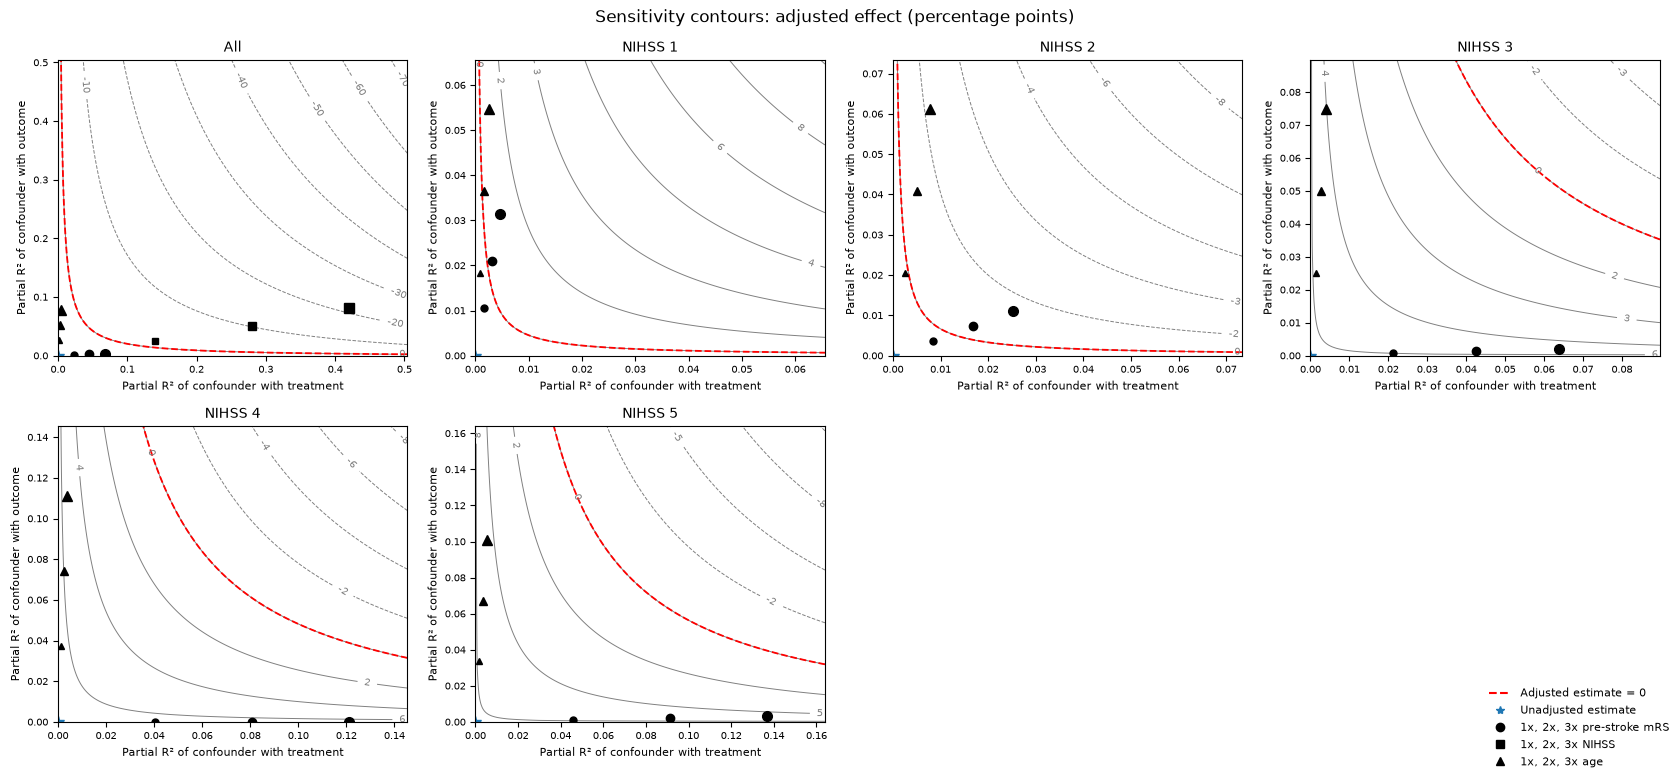

In [34]:
plot_sensemakr_contours(sensemakr_stats, sensemakr_bounds, SENS_LABELS, output_path("sensemakr_contours.png"))

**Results.** The linear probability model gives effects similar to the S-learner: 5.2 percentage points overall (95% CI 4.3 to 6.1).

| Group | n | Estimate, points (95% CI) | Partial R² of treatment | RV_q | RV_q,α |
|---|---|---|---|---|---|
| All | 58,387 | 5.2 (4.3 to 6.1) | 0.22% | 4.6% | 3.8% |
| NIHSS 1 | 11,002 | −1.0 (−3.8 to 1.8) | 0.00% | 0.7% | 0.0% |
| NIHSS 2 | 14,145 | 1.0 (−1.0 to 3.1) | 0.01% | 0.8% | 0.0% |
| NIHSS 3 | 12,855 | 6.4 (4.5 to 8.3) | 0.35% | 5.7% | 4.1% |
| NIHSS 4 | 10,967 | 7.3 (5.5 to 9.2) | 0.53% | 7.1% | 5.3% |
| NIHSS 5 | 9,418 | 8.0 (6.0 to 10.1) | 0.62% | 7.6% | 5.7% |

* **Overall.** An unmeasured confounder would need to explain 4.6% of the remaining variance of both thrombolysis and outcome to remove the estimate, and 3.8% to make it non-significant.
* **Benchmarks for the overall estimate.**
  * A confounder up to 3 times as strong as pre-stroke mRS or age would leave a clear benefit: 3.6 (2.7 to 4.5) and 3.3 (2.4 to 4.2) points.
  * A confounder as strong as NIHSS would reverse it: −1.7 (−2.7 to −0.8) points. NIHSS is by far the strongest determinant of treatment, so a confounder of comparable strength is a real concern for the pooled estimate.
* **Within NIHSS strata** this dominant source of selection is removed.
  * NIHSS 3–5: robustness values are 5.7–7.6%. Benchmark confounders up to 3 times as strong as pre-stroke mRS or age leave benefits of 4.6–7.2 points, all with CIs above zero.
  * NIHSS 1–2: the estimates are close to zero with CIs that include zero, and a confounder explaining less than 1% of residual variance would remove them.
* **Contour plots.** These show the adjusted estimate for any combination of confounder strengths (red dashed line: adjusted estimate = 0), with the benchmarks marked.
  * Whole cohort: the age and pre-stroke mRS benchmarks lie on the positive side of the zero line, and the NIHSS benchmarks lie well beyond it.
  * NIHSS 3–5: all benchmarks lie well inside the region of positive effect.
  * NIHSS 1–2: the zero line runs close to the origin, and the benchmarks lie on or beyond it.

## S5. Leave-one-out analysis of the main confounders

The three strongest measured confounders are NIHSS, age and pre-stroke mRS. Each is removed from the S-learner features in turn, and the model is refitted with the same tuned hyperparameters and cross-validation folds.

Leaving out a measured confounder is a deliberate misspecification. The change in the estimated effect in thrombolysed patients shows how much each result depends on adjusting for that confounder. It also suggests how much bias an unmeasured confounder of similar strength, acting in the same direction, could cause.

Results by NIHSS use each thrombolysed patient's NIHSS, also when NIHSS is left out of the model.

In [35]:
# Leave-one-out sensitivity analysis: remove each main confounder from the S-learner features in turn,
# refitting with the same tuned hyperparameters and cross-validation folds
LOO_FEATURES = {
    "Without NIHSS": "stroke_severity",
    "Without age": "age",
    "Without pre-stroke mRS": "prior_disability",
}

def loo_rows(cf_, analysis, auc):
    """Mean effect overall and by NIHSS for one analysis, with the model's mean out-of-fold AUC."""
    estimates = effect_estimates(cf_).reset_index()
    estimates["analysis"] = analysis
    estimates["mean AUC"] = auc
    return estimates

loo_results = [loo_rows(cf, "Primary", performance["AUC"].mean())]
for label, feature in LOO_FEATURES.items():
    cf_loo, performance_loo = run_thrombolysis_analysis(data, features=[f for f in X_FIELDS if f != feature])
    # NIHSS of each thrombolysed patient, for the by-NIHSS summaries (needed when NIHSS is left out)
    cf_loo["stroke_severity"] = data.loc[cf_loo["patient_index"], "stroke_severity"].to_numpy()
    loo_results.append(loo_rows(cf_loo, label, performance_loo["AUC"].mean()))
    print(f"Completed: {label}")

loo_df = pd.concat(loo_results, ignore_index=True)
loo_df["prob_diff_pp"] = 100 * loo_df["prob_diff"]
primary_pp = loo_df[loo_df["analysis"] == "Primary"].set_index("group")["prob_diff_pp"]
loo_df["change_pp"] = loo_df["prob_diff_pp"] - loo_df["group"].map(primary_pp)
loo_df.to_csv(output_path("leave_one_out.csv"), index=False)

loo_columns = ["Primary", *LOO_FEATURES]
for values, title, decimals in [
    ("prob_diff_pp", "Mean benefit in thrombolysed patients, percentage points", 1),
    ("log_odds_diff", "Mean benefit, log odds ratio", 3),
    ("change_pp", "Change from the primary estimate, percentage points", 1),
]:
    print(title)
    display(loo_df.pivot(index="group", columns="analysis", values=values)
            .reindex(index=EFFECT_GROUPS, columns=loo_columns).round(decimals))
print("Mean out-of-fold AUC:",
      loo_df.drop_duplicates("analysis").set_index("analysis")["mean AUC"].round(3).to_dict())

Completed: Without NIHSS
Completed: Without age
Completed: Without pre-stroke mRS
Mean benefit in thrombolysed patients, percentage points


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
group,,,,
All,5.0,-0.5,5.8,5.4
NIHSS 1,0.7,-0.6,0.7,0.9
NIHSS 2,1.7,-0.6,2.0,2.2
NIHSS 3,4.2,-0.5,5.1,4.9
NIHSS 4,6.1,-0.5,7.0,6.5
NIHSS 5,6.8,-0.4,7.5,6.9


Mean benefit, log odds ratio


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
group,,,,
All,0.292,-0.030,0.323,0.314
NIHSS 1,0.057,-0.039,0.060,0.079
NIHSS 2,0.130,-0.036,0.153,0.171
NIHSS 3,0.276,-0.030,0.322,0.313
NIHSS 4,0.350,-0.030,0.386,0.370
NIHSS 5,0.358,-0.026,0.379,0.362


Change from the primary estimate, percentage points


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
group,,,,
All,0.0,-5.5,0.8,0.4
NIHSS 1,0.0,-1.3,0.1,0.2
NIHSS 2,0.0,-2.3,0.4,0.5
NIHSS 3,0.0,-4.7,1.0,0.7
NIHSS 4,0.0,-6.5,1.0,0.5
NIHSS 5,0.0,-7.2,0.8,0.2


Mean out-of-fold AUC: {'Primary': 0.724, 'Without NIHSS': 0.706, 'Without age': 0.7, 'Without pre-stroke mRS': 0.702}


**Results.**

| Model | All | NIHSS 1 | NIHSS 2 | NIHSS 3 | NIHSS 4 | NIHSS 5 | AUC |
|---|---|---|---|---|---|---|---|
| Primary | 5.0 | 0.7 | 1.7 | 4.2 | 6.1 | 6.8 | 0.724 |
| Without NIHSS | −0.5 | −0.6 | −0.6 | −0.5 | −0.5 | −0.4 | 0.706 |
| Without age | 5.8 | 0.7 | 2.0 | 5.1 | 7.0 | 7.5 | 0.700 |
| Without pre-stroke mRS | 5.4 | 0.9 | 2.2 | 4.9 | 6.5 | 6.9 | 0.702 |

*(Mean benefit in thrombolysed patients, percentage points; mean out-of-fold AUC.)*

* **Without NIHSS** the estimated benefit disappears: −0.5 points, a change of −5.5 points overall and of −1.3 to −7.2 points by NIHSS. Thrombolysed patients have more severe strokes, which carry a worse prognosis, so failing to adjust for severity biases the estimate strongly *against* thrombolysis. The model also loses the severity gradient, giving the same small negative effect at every NIHSS.
* **Without age or pre-stroke mRS** the benefit increases slightly: by 0.8 and 0.4 points overall, and by up to 1.0 point by NIHSS. Thrombolysed patients are younger and less disabled, so omitting these factors biases the estimate in favour of thrombolysis, but only modestly.

So the estimates depend critically on adjustment for stroke severity. An unmeasured confounder that acts like NIHSS, such as whether the deficit is disabling, would most likely lead the model to *underestimate* benefit. An unmeasured confounder as strong as age or pre-stroke mRS, acting in their direction, would inflate the benefit by about 1 point or less.

## S6. Further sensitivity analyses to consider (not run here)

* **Alternative meta-learners.** Compare with a T-learner (separate treated and untreated models), an X-learner, a doubly robust (DR) learner or a causal forest (e.g. `econml`). Doubly robust methods combine the outcome and propensity models and reduce reliance on either being correct.
* **Nested tuning.** Re-tune hyperparameters within each training fold to remove the small optimism of tuning on all patients.
* **Instrumental variable analysis.** Between-hospital variation in thrombolysis use for mild stroke is large. Hospital thrombolysis rate (in mild stroke) can be used as an instrument. Under its own assumptions, this addresses unmeasured patient-level confounding, such as a disabling vs non-disabling deficit.
* **Placebo / negative-control tests.**
  * (a) Randomly reassign thrombolysis times among treated patients: any time gradient should disappear.
  * (b) Use a negative-control outcome that thrombolysis cannot plausibly affect but that shares confounders.
* **Quantitative bias analysis** for a specified unmeasured confounder, to complement E-values and sensemakr. An example is the prevalence of disabling deficits in treated vs untreated patients, and their effect on outcome.
* **Comparison with trial evidence.** Trials of thrombolysis in minor, non-disabling stroke (e.g. PRISMS, ARAMIS) have not shown benefit over antiplatelet therapy. Restricting to the patients most like trial populations, where data allow, would directly check whether the observational estimate is consistent.
* **Missing data and selection.** Compare native missing-value handling with multiple imputation; vary the arrival window; include patients who had perfusion imaging.

# 7. Summary of observations and conclusions

## Observations

1. **Population and selection.** 58,387 patients with mild ischaemic stroke (NIHSS 1–5) arrived within 4 hours; 22.9% received thrombolysis. Treatment depended strongly on severity (7% at NIHSS 1 to 44% at NIHSS 5), age, pre-stroke disability and anticoagulant use. The propensity model had an AUC of 0.79.
2. **Model quality.**
   * The tuned XGBoost outcome model had moderate discrimination (AUC 0.72).
   * It was well calibrated: intercept 0.00, slope 0.98, and agreement within about 1 point in every decile.
   * This matters because treatment effects are differences between predicted probabilities.
3. **Average benefit.** In thrombolysed patients, thrombolysis was associated with a **5.0 percentage-point** higher probability of good discharge outcome (bootstrap 95% CI 4.2 to 5.9). The corresponding OR is 1.34 (1.27 to 1.41).
4. **Time to treatment.**
   * Benefit declined steadily with delay, by about 0.15 log odds ratio per hour.
   * It was greatest within 2 hours (log OR about 0.5) and small after 4 hours (about 0.08).
   * The fitted benefit reached zero at about 295 minutes (bootstrap 95% CI 263 to 328).
5. **Severity.** Benefit rose with NIHSS:
   * NIHSS 1: 0.7 points (−0.3 to 1.6), **no detectable benefit**. Overlap between treated and untreated patients is also poorest here.
   * NIHSS 2: 1.7 points (0.9 to 2.5).
   * NIHSS 3: 4.2 points.
   * NIHSS 4–5: 6.1–6.8 points.
6. **Other heterogeneity.**
   * Benefit was smaller in patients over about 80, in those with more pre-stroke disability, and in those with diabetes.
   * Variation between stroke teams was moderate.
   * Most of the variation in estimated benefit was explained by patient features and team (meta-model out-of-fold R² 0.89).
7. **Robustness to analytic choices.**
   * With the primary outcome, the average benefit was 4.6 to 5.3 points in every tuned, regularised or logistic scenario.
   * The time gradient and zero point were stable (−0.12 to −0.16 per hour; 279–323 minutes).
   * Benefit at NIHSS 1 stayed close to zero in all flexible models.
   * Default XGBoost settings, especially with class weighting, gave larger but noisier and worse-calibrated estimates.
8. **Unmeasured confounding.**
   * The overall E-value is 1.58, and the sensemakr robustness value 4.6%.
   * The average estimate withstands a confounder up to 3 times as strong as age or pre-stroke mRS, but not one as strong as NIHSS.
   * Within NIHSS 3–5, estimates are more robust (robustness values 5.7–7.6%).
   * Estimates at NIHSS 1–2, and for treatment after 4 hours, could be explained away by weak confounding.
9. **Dependence on severity adjustment.**
   * Leaving NIHSS out removed the benefit entirely (−0.5 points), because treated patients have more severe strokes.
   * Leaving out age or pre-stroke mRS increased the benefit by less than 1 point.

## Comparison with trial evidence

Randomised trials in minor, *non-disabling* ischaemic stroke have not shown a benefit of thrombolysis. Examples are PRISMS (alteplase vs aspirin) and ARAMIS (dual antiplatelet therapy vs alteplase). These results are broadly consistent with that: the estimated benefit is modest, absent at NIHSS 1 and small at NIHSS 2.

The benefit at NIHSS 3–5 and with early treatment may reflect a real effect in patients with *disabling* deficits, in whom thrombolysis is recommended. These data cannot separate disabling from non-disabling deficits.

Other differences from the trials:
* the comparator is usual care, not necessarily dual antiplatelet therapy;
* outcome is measured at discharge rather than at 90 days;
* there may be residual confounding.

## Conclusions

* In mild stroke, thrombolysis is associated with a modest average improvement in good outcome at discharge (about 5 percentage points). The benefit is concentrated in patients treated early and in those with NIHSS 3–5.
* There is no detectable benefit at NIHSS 1, and only a small, fragile benefit at NIHSS 2.
* Benefit declines steadily with time and is close to zero beyond about 4.5–5 hours from onset.
* The estimates depend critically on adjustment for stroke severity. The most plausible unmeasured confounder, whether a deficit is disabling, acts like severity and would most likely bias the estimates *against* thrombolysis. Other unrecorded factors could bias in either direction.

## Limitations

* **Observational data.** Causal interpretation requires no unmeasured confounding. Treatment selection in mild stroke depends on clinical judgement that is only partly recorded.
* **Outcome.** It is measured at discharge, not at 90 days.
* **Effect measure.** Effects are averages of model-based individual (conditional) estimates in thrombolysed patients. They are not marginal effects, and individual estimates are not validated against individual outcomes.
* **Overlap.** It is poor at NIHSS 1, so estimates there rely on extrapolation.
* **Tuning.** Hyperparameters were tuned on all patients (non-nested); the bootstrap held them fixed.
* **Sensemakr.** It uses a linear probability model as a stand-in for the S-learner.

Further analyses that would strengthen the conclusions are listed in S6, notably a doubly robust learner and an instrumental variable analysis using between-hospital variation.